In [1]:
# ============================================
# STEP 1: INSTALL LIBRARIES
# ============================================

!pip install duckdb pandas numpy scikit-learn xgboost lightgbm matplotlib seaborn

print("✅ Libraries installed!")

   ---------------------------------------- 0.0/13.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/13.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/13.1 MB ? eta -:--:--
    --------------------------------------- 0.3/13.1 MB ? eta -:--:--
   -- ------------------------------------- 0.8/13.1 MB 1.6 MB/s eta 0:00:08
   ------ --------------------------------- 2.1/13.1 MB 3.4 MB/s eta 0:00:04
   ------ --------------------------------- 2.1/13.1 MB 3.4 MB/s eta 0:00:04
   --------- ------------------------------ 3.1/13.1 MB 3.3 MB/s eta 0:00:04
   --------------- ------------------------ 5.0/13.1 MB 4.2 MB/s eta 0:00:02
   --------------- ------------------------ 5.2/13.1 MB 4.2 MB/s eta 0:00:02
   --------------------- ------------------ 7.1/13.1 MB 4.4 MB/s eta 0:00:02
   -------------------------- ------------- 8.7/13.1 MB 4.8 MB/s eta 0:00:01
   ------------------------------ --------- 10.0/13.1 MB 5.0 MB/s eta 0:00:01
   -----------------------

In [2]:
# ============================================
# STEP 2: IMPORTS & CONFIGURATION
# ============================================

import sys
import os
import duckdb
import pandas as pd
import numpy as np
import warnings
from datetime import datetime

warnings.filterwarnings('ignore')

print("=" * 60)
print("FYP PREPROCESSING PIPELINE")
print("=" * 60)

# ⭐⭐⭐ UPDATE THIS PATH TO YOUR MIMIC FOLDER ⭐⭐⭐
MIMIC_ROOT = r"D:/abc4/IoT-Pneumonia Dataset/mimic-iv-3.1"  # CHANGE THIS!

# Set folder paths
hosp_path = os.path.join(MIMIC_ROOT, "hosp")
icu_path = os.path.join(MIMIC_ROOT, "icu")

# File paths
PATIENTS_FILE = os.path.join(hosp_path, "patients.csv")
ADMISSIONS_FILE = os.path.join(hosp_path, "admissions.csv")
DIAGNOSES_FILE = os.path.join(hosp_path, "diagnoses_icd.csv")
D_ICD_FILE = os.path.join(hosp_path, "d_icd_diagnoses.csv")
LABEVENTS_FILE = os.path.join(hosp_path, "labevents.csv")
CHARTEVENTS_FILE = os.path.join(icu_path, "chartevents.csv")

print(f"\n📁 MIMIC Root: {MIMIC_ROOT}")
print(f"   hosp folder exists: {os.path.exists(hosp_path)}")
print(f"   icu folder exists: {os.path.exists(icu_path)}")

# Verify files
print("\n📋 File Status:")
files_ok = True
for name, path in [
    ("Patients", PATIENTS_FILE),
    ("Admissions", ADMISSIONS_FILE),
    ("Diagnoses", DIAGNOSES_FILE),
    ("ICD Codes", D_ICD_FILE),
    ("Lab Events", LABEVENTS_FILE),
    ("Chart Events", CHARTEVENTS_FILE),
]:
    if os.path.exists(path):
        if name == "Chart Events":
            size_gb = os.path.getsize(path) / (1024**3)
            print(f"   ✅ {name}: {size_gb:.1f} GB")
        else:
            size_mb = os.path.getsize(path) / (1024**2)
            print(f"   ✅ {name}: {size_mb:.1f} MB")
    else:
        print(f"   ❌ {name}: NOT FOUND")
        files_ok = False

if not files_ok:
    print("\n⚠️ Some files missing. Please update MIMIC_ROOT path!")
else:
    print("\n✅ All files found!")

FYP PREPROCESSING PIPELINE

📁 MIMIC Root: D:/abc4/IoT-Pneumonia Dataset/mimic-iv-3.1
   hosp folder exists: True
   icu folder exists: True

📋 File Status:
   ✅ Patients: 11.5 MB
   ✅ Admissions: 89.8 MB
   ✅ Diagnoses: 173.0 MB
   ✅ ICD Codes: 8.7 MB
   ✅ Lab Events: 17550.3 MB
   ✅ Chart Events: 39.1 GB

✅ All files found!


In [3]:
# ============================================
# STEP 3: FEATURE MAPPINGS
# ============================================

# 🫁 PHYSIOLOGICAL FEATURES (from chartevents)
PHYSIOLOGICAL_FEATURES = {
    220045: 'heart_rate',
    220277: 'spo2',
    220210: 'respiratory_rate',
    223762: 'temperature',
    223761: 'temperature',
    220179: 'sbp',
}

# 🤒 SYMPTOM FEATURES (from diagnoses_icd)
SYMPTOM_FEATURES = {
    'dyspnea': ['R06.0', 'R06.00', 'R06.02', 'J98.01', 'R06.09'],
    'cough': ['R05', 'R05.0', 'R05.1', 'R05.8', 'R05.9'],
    'fever': ['R50.9', 'R50.8', 'R50.81', 'R50.82', 'R68.83'],
    'chest_pain': ['R07.9', 'R07.89', 'R07.1', 'R07.2', 'R07.82'],
    'hypoxemia': ['R09.02', 'J96.01', 'J96.11', 'R09.2'],
    'respiratory_distress': ['J80', 'R06.03', 'J96.0', 'J96.1', 'R06.00'],
    'fatigue': ['R53.83', 'R53.8', 'R53.1', 'R53.81'],
}

# 👤 COMORBIDITIES
COMORBIDITIES = {
    'copd': ['J44.9', 'J44.8', 'J44.0', 'J43.9', 'J41.0', 'J42', 'J43'],
    'asthma': ['J45.90', 'J45.40', 'J45.901', 'J45.909', 'J45.41', 'J45.42'],
    'diabetes': ['E11.9', 'E11.8', 'E11.65', 'E11.64', 'E10.9', 'E10.8'],
}

BATCH_SIZE = 200  # Smaller batches for stability

print("✅ Feature mappings loaded")
print(f"   Physiological features: {len(PHYSIOLOGICAL_FEATURES)}")
print(f"   Symptom features: {len(SYMPTOM_FEATURES)}")
print(f"   Comorbidities: {len(COMORBIDITIES)}")

✅ Feature mappings loaded
   Physiological features: 6
   Symptom features: 7
   Comorbidities: 3


In [4]:
# ============================================
# STEP 4: FIND PNEUMONIA PATIENTS (BALANCED)
# ============================================

print("\n" + "=" * 60)
print("STEP 1: Finding Pneumonia Patients (Balanced)")
print("=" * 60)

# Get pneumonia ICD codes
query_icd = f"""
SELECT DISTINCT icd_code 
FROM read_csv_auto('{D_ICD_FILE}')
WHERE LOWER(long_title) LIKE '%pneumonia%'
   OR (icd_code >= 'J12' AND icd_code <= 'J18')
"""
pneumonia_icd = duckdb.sql(query_icd).df()
print(f"✅ Found {len(pneumonia_icd)} pneumonia ICD codes")

# Get pneumonia admissions
icd_list = "','".join(pneumonia_icd['icd_code'].tolist())
query_pneumonia = f"""
SELECT DISTINCT d.hadm_id, d.subject_id, a.admittime
FROM read_csv_auto('{DIAGNOSES_FILE}') d
JOIN read_csv_auto('{ADMISSIONS_FILE}') a ON d.hadm_id = a.hadm_id
WHERE d.icd_code IN ('{icd_list}')
"""
pneumonia_df = duckdb.sql(query_pneumonia).df()
pneumonia_hadm_ids = pneumonia_df['hadm_id'].unique().tolist()
n_pneumonia = len(pneumonia_hadm_ids)
print(f"✅ Found {n_pneumonia} pneumonia admissions")

# Get EQUAL number of controls (BALANCED DATASET)
query_control = f"""
SELECT hadm_id, subject_id, admittime
FROM read_csv_auto('{ADMISSIONS_FILE}')
WHERE hadm_id NOT IN (SELECT hadm_id FROM pneumonia_df)
ORDER BY RANDOM()
LIMIT {n_pneumonia}
"""
control_df = duckdb.sql(query_control).df()
control_hadm_ids = control_df['hadm_id'].unique().tolist()
print(f"✅ Found {len(control_hadm_ids)} control admissions (balanced)")

# Combine
all_hadm_ids = pneumonia_hadm_ids + control_hadm_ids
labels = [1] * n_pneumonia + [0] * n_pneumonia

print(f"\n✅ TOTAL: {len(all_hadm_ids)} patients")
print(f"   Pneumonia: {sum(labels)}")
print(f"   Control: {len(labels) - sum(labels)}")
print(f"   ✅ PERFECTLY BALANCED!")

# Save patient list
patient_df = pd.DataFrame({'hadm_id': all_hadm_ids, 'pneumonia_label': labels})
patient_df.to_csv("patient_list.csv", index=False)
print("   💾 Saved patient_list.csv")


STEP 1: Finding Pneumonia Patients (Balanced)
✅ Found 152 pneumonia ICD codes
✅ Found 35895 pneumonia admissions
✅ Found 35895 control admissions (balanced)

✅ TOTAL: 71790 patients
   Pneumonia: 35895
   Control: 35895
   ✅ PERFECTLY BALANCED!
   💾 Saved patient_list.csv


In [5]:
# ============================================
# OPTIONAL: TEST WITH SUBSET FIRST
# ============================================

print("\n" + "=" * 60)
print("OPTIONAL: Test with Subset")
print("=" * 60)

# Use 10% for testing
TEST_SIZE = 0.1  # Change to 0.05 for 5%, 0.2 for 20%

import random
random.seed(42)  # For reproducibility

test_hadm_ids = random.sample(all_hadm_ids, int(len(all_hadm_ids) * TEST_SIZE))

print(f"📊 Test subset: {len(test_hadm_ids)} patients ({TEST_SIZE*100:.0f}% of data)")
print(f"   Pneumonia: {sum([1 for id in test_hadm_ids if id in pneumonia_hadm_ids])}")
print(f"   Control: {len(test_hadm_ids) - sum([1 for id in test_hadm_ids if id in pneumonia_hadm_ids])}")

# Use test_hadm_ids for Step 5 instead of all_hadm_ids
# all_hadm_ids_for_step5 = test_hadm_ids  # For testing
all_hadm_ids_for_step5 = all_hadm_ids  # For full run - CHANGE THIS

print(f"\n✅ Using {len(all_hadm_ids_for_step5)} patients for Step 5")
print("   Change all_hadm_ids_for_step5 to test or full dataset")


OPTIONAL: Test with Subset
📊 Test subset: 7179 patients (10% of data)
   Pneumonia: 3534
   Control: 3645

✅ Using 71790 patients for Step 5
   Change all_hadm_ids_for_step5 to test or full dataset


In [6]:
# ============================================
# STEP 5: EXTRACT PHYSIOLOGICAL FEATURES
# ============================================

print("\n" + "=" * 60)
print("STEP 2: Extracting Physiological Features")
print(f"Start time: {datetime.now().strftime('%H:%M:%S')}")
print("=" * 60)

# Create connection with error handling
conn = duckdb.connect(':memory:')

# Create view with error handling
try:
    conn.execute(f"""
    CREATE OR REPLACE VIEW chartevents_view AS 
    SELECT * FROM read_csv_auto('{CHARTEVENTS_FILE}', 
        ignore_errors=true, 
        null_padding=true,
        parallel=true
    )
    """)
    print("✅ Created chartevents view")
except Exception as e:
    print(f"⚠️ Could not create view: {e}")
    conn = duckdb.connect(':memory:')

def extract_vitals(batch_ids):
    """Extract vitals for a batch of patients"""
    if len(batch_ids) == 0:
        return pd.DataFrame()
    
    hadmids_str = ','.join(map(str, batch_ids))
    itemids = list(PHYSIOLOGICAL_FEATURES.keys())
    itemids_str = ','.join(map(str, itemids))
    
    query = f"""
    SELECT hadm_id, itemid, valuenum, charttime
    FROM chartevents_view
    WHERE hadm_id IN ({hadmids_str})
      AND itemid IN ({itemids_str})
      AND valuenum IS NOT NULL
      AND valuenum > 0
      AND valuenum < 10000
      AND charttime IS NOT NULL
    """
    
    try:
        df = conn.execute(query).df()
        if df.empty:
            return pd.DataFrame()
        
        # Map itemid to feature names
        df['feature'] = df['itemid'].map(PHYSIOLOGICAL_FEATURES)
        df = df.dropna(subset=['feature'])
        
        # Convert charttime safely
        df['charttime'] = pd.to_datetime(df['charttime'], errors='coerce')
        df = df.dropna(subset=['charttime'])
        
        return df[['hadm_id', 'feature', 'valuenum', 'charttime']]
        
    except Exception as e:
        print(f"      Error: {str(e)[:100]}")
        return pd.DataFrame()

# Process in batches
physio_dfs = []
total_batches = (len(all_hadm_ids) // BATCH_SIZE) + 1

successful_batches = 0

print(f"\n📊 Processing {len(all_hadm_ids)} patients in {total_batches} batches...")

for i in range(0, len(all_hadm_ids), BATCH_SIZE):
    batch = all_hadm_ids[i:i+BATCH_SIZE]
    batch_num = i // BATCH_SIZE + 1
    print(f"   Batch {batch_num}/{total_batches} ({len(batch)} patients)")
    
    batch_df = extract_vitals(batch)
    
    if not batch_df.empty:
        physio_dfs.append(batch_df)
        successful_batches += 1
        print(f"      ✅ Got {len(batch_df)} measurements")
    else:
        print(f"      ⚠️ No vitals found")
    
    # Save progress every 10 batches
    if len(physio_dfs) > 0 and batch_num % 10 == 0:
        temp_df = pd.concat(physio_dfs, ignore_index=True)
        temp_df.to_csv("vitals_progress.csv", index=False)
        print(f"   💾 Progress saved (batch {batch_num})")

conn.close()

print(f"\n📊 Summary: {successful_batches} batches with data")

if physio_dfs:
    vitals_df = pd.concat(physio_dfs, ignore_index=True)
    print(f"\n✅ Total extracted: {len(vitals_df)} vital sign measurements")
    
    # Remove duplicates
    vitals_df = vitals_df.drop_duplicates(subset=['hadm_id', 'charttime', 'feature'])
    print(f"✅ After deduplication: {len(vitals_df)} measurements")
    
    # Save
    vitals_df.to_csv("vitals_raw.csv", index=False)
    print("💾 Saved vitals_raw.csv")
    
else:
    vitals_df = pd.DataFrame()
    print("❌ No vitals extracted!")


STEP 2: Extracting Physiological Features
Start time: 10:08:35
✅ Created chartevents view

📊 Processing 71790 patients in 359 batches...
   Batch 1/359 (200 patients)


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

      ✅ Got 64413 measurements
   Batch 2/359 (200 patients)


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

      ✅ Got 50515 measurements
   Batch 3/359 (200 patients)


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

... (709 outputs left out)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

      ✅ Got 3963 measurements
   Batch 359/359 (190 patients)


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

      ✅ Got 1770 measurements

📊 Summary: 306 batches with data

✅ Total extracted: 5305872 vital sign measurements
✅ After deduplication: 5305180 measurements
💾 Saved vitals_raw.csv


In [7]:
# ============================================
# MORNING CHECK: STEP 5 VERIFICATION
# ============================================

import pandas as pd
import numpy as np

print("=" * 60)
print("📊 STEP 5 VERIFICATION")
print("=" * 60)

# Load the vitals data
vitals_df = pd.read_csv("vitals_raw.csv")
vitals_df['charttime'] = pd.to_datetime(vitals_df['charttime'])

print(f"✅ Loaded {len(vitals_df):,} measurements")
print(f"   Unique patients: {vitals_df['hadm_id'].nunique():,}")
print(f"   Features extracted: {vitals_df['feature'].nunique()}")

# Check feature distribution
print("\n📋 Measurements per feature:")
feature_counts = vitals_df['feature'].value_counts()
for feature, count in feature_counts.items():
    print(f"   {feature}: {count:,} ({count/len(vitals_df)*100:.1f}%)")

# Check measurements per patient
measurements_per_patient = vitals_df.groupby('hadm_id').size()
print(f"\n📊 Measurements per patient:")
print(f"   Min: {measurements_per_patient.min()}")
print(f"   Max: {measurements_per_patient.max()}")
print(f"   Avg: {measurements_per_patient.mean():.1f}")
print(f"   Median: {measurements_per_patient.median():.1f}")

# Check time range
print(f"\n📅 Time range:")
print(f"   Min: {vitals_df['charttime'].min()}")
print(f"   Max: {vitals_df['charttime'].max()}")

# Check for missing values
print(f"\n✅ Missing values: {vitals_df.isnull().sum().sum()} (should be 0)")

print("\n🎉 Step 5 complete! Ready for Step 6!")

📊 STEP 5 VERIFICATION
✅ Loaded 5,305,180 measurements
   Unique patients: 7,647
   Features extracted: 5

📋 Measurements per feature:
   heart_rate: 1,383,882 (26.1%)
   respiratory_rate: 1,365,431 (25.7%)
   spo2: 1,364,880 (25.7%)
   sbp: 801,540 (15.1%)
   temperature: 389,447 (7.3%)

📊 Measurements per patient:
   Min: 2
   Max: 19756
   Avg: 693.8
   Median: 337.0

📅 Time range:
   Min: 2110-01-18 19:00:00
   Max: 2213-05-02 18:00:00

✅ Missing values: 0 (should be 0)

🎉 Step 5 complete! Ready for Step 6!


In [8]:
# ============================================
# STEP 6: CREATE PATIENT-LEVEL FEATURES
# ============================================

print("\n" + "=" * 60)
print("STEP 6: Creating Patient-Level Features")
print("=" * 60)

# Load vitals data
vitals_df = pd.read_csv("vitals_raw.csv")
vitals_df['charttime'] = pd.to_datetime(vitals_df['charttime'])

print(f"✅ Loaded {len(vitals_df):,} measurements")
print(f"   Unique patients: {vitals_df['hadm_id'].nunique():,}")

# Calculate hours since first measurement per patient
vitals_df['hours_since_admission'] = vitals_df.groupby('hadm_id')['charttime'].transform(
    lambda x: (x - x.min()).dt.total_seconds() / 3600
)
vitals_df['day_number'] = (vitals_df['hours_since_admission'] // 24).astype(int) + 1

# Filter to first 7 days
vitals_df = vitals_df[vitals_df['day_number'] <= 7]
print(f"✅ Filtered to first 7 days: {len(vitals_df)} measurements")

# Aggregate per patient
aggregated = vitals_df.groupby(['hadm_id', 'feature']).agg({
    'valuenum': ['mean', 'min', 'max', 'std'],
    'hours_since_admission': lambda x: np.polyfit(range(len(x)), x, 1)[0] if len(x) > 1 else 0
}).reset_index()

aggregated.columns = ['hadm_id', 'feature', 'mean', 'min', 'max', 'std', 'trend']

# Pivot to wide format
patient_features = aggregated.pivot(index='hadm_id', columns='feature', 
                                     values=['mean', 'min', 'max', 'std', 'trend'])
patient_features.columns = [f'{col[1]}_{col[0]}' for col in patient_features.columns]
patient_features = patient_features.reset_index()

print(f"\n✅ Created patient-level features:")
print(f"   Patients: {len(patient_features)}")
print(f"   Features: {len(patient_features.columns)}")

# Save
patient_features.to_csv("patient_features.csv", index=False)
print("💾 Saved patient_features.csv")


STEP 6: Creating Patient-Level Features
✅ Loaded 5,305,180 measurements
   Unique patients: 7,647
✅ Filtered to first 7 days: 2883778 measurements

✅ Created patient-level features:
   Patients: 7647
   Features: 26
💾 Saved patient_features.csv


In [9]:
# ============================================
# CHECK CLASS DISTRIBUTION BEFORE STEP 7
# ============================================

import pandas as pd

print("=" * 60)
print("📊 CLASS DISTRIBUTION CHECK")
print("=" * 60)

# Load the patient list from Step 4
patient_df = pd.read_csv("patient_list.csv")
print(f"✅ Loaded patient_list.csv")
print(f"   Total patients: {len(patient_df):,}")

# Check original distribution
print(f"\n📊 Original Distribution (from Step 4):")
print(f"   Pneumonia: {patient_df['pneumonia_label'].sum():,}")
print(f"   Control: {len(patient_df) - patient_df['pneumonia_label'].sum():,}")
print(f"   Balance: {'✅ YES' if patient_df['pneumonia_label'].sum() == len(patient_df) - patient_df['pneumonia_label'].sum() else '⚠️ Not perfect'}")

# Load patient features from Step 6 (only those with vitals data)
patient_features = pd.read_csv("patient_features.csv")
print(f"\n📊 Step 6 Patients (with vitals data):")
print(f"   Total patients: {len(patient_features):,}")

# Get the pneumonia labels for these patients
# Merge with patient_list to get labels
merged = patient_features.merge(patient_df, on='hadm_id', how='left')
pneumonia_count = merged['pneumonia_label'].sum()
control_count = len(merged) - pneumonia_count

print(f"\n📊 Final Distribution (Step 6 patients with vitals):")
print(f"   Pneumonia: {pneumonia_count:,}")
print(f"   Control: {control_count:,}")
print(f"   Total: {len(merged):,}")
print(f"   Balance: {'✅ YES' if pneumonia_count == control_count else f'⚠️ Difference: {abs(pneumonia_count - control_count)}'}")

# Show percentage
print(f"\n📊 Percentage Breakdown:")
print(f"   Pneumonia: {pneumonia_count/len(merged)*100:.1f}%")
print(f"   Control: {control_count/len(merged)*100:.1f}%")

📊 CLASS DISTRIBUTION CHECK
✅ Loaded patient_list.csv
   Total patients: 71,790

📊 Original Distribution (from Step 4):
   Pneumonia: 35,895
   Control: 35,895
   Balance: ✅ YES

📊 Step 6 Patients (with vitals data):
   Total patients: 7,647

📊 Final Distribution (Step 6 patients with vitals):
   Pneumonia: 5,719
   Control: 1,928
   Total: 7,647
   Balance: ⚠️ Difference: 3791

📊 Percentage Breakdown:
   Pneumonia: 74.8%
   Control: 25.2%


In [11]:
# ============================================
# PRIORITY INVESTIGATION: WHY 90% PATIENTS LOST? (FIXED)
# ============================================

import pandas as pd
import duckdb
import os
import numpy as np

print("=" * 70)
print("🔍 PATIENT LOSS INVESTIGATION")
print("=" * 70)

# Load data
patient_df = pd.read_csv("patient_list.csv")
patient_features = pd.read_csv("patient_features.csv")

print(f"\n📊 Step 4: {len(patient_df):,} patients")
print(f"   Pneumonia: {patient_df['pneumonia_label'].sum():,}")
print(f"   Control: {len(patient_df) - patient_df['pneumonia_label'].sum():,}")

print(f"\n📊 Step 6: {len(patient_features):,} patients")

# Get labels for Step 6 patients by merging
merged = patient_features.merge(patient_df, on='hadm_id', how='left')
pneumonia_count = merged['pneumonia_label'].sum()
control_count = len(merged) - pneumonia_count

print(f"   Pneumonia: {pneumonia_count:,}")
print(f"   Control: {control_count:,}")

print(f"\n📊 Loss: {len(patient_df) - len(patient_features):,} patients ({(1 - len(patient_features)/len(patient_df))*100:.1f}%)")

# ============================================
# Q1: Check hadm_id vs subject_id
# ============================================

print("\n" + "=" * 70)
print("📋 Q1: hadm_id vs subject_id")
print("=" * 70)

conn = duckdb.connect(':memory:')

# Get admissions file path
ADMISSIONS_FILE = os.path.join(hosp_path, "admissions.csv")

query = f"""
SELECT 
    COUNT(DISTINCT hadm_id) as unique_hadm,
    COUNT(DISTINCT subject_id) as unique_subjects
FROM read_csv_auto('{ADMISSIONS_FILE}')
"""
result = conn.execute(query).df()
print(f"Admissions file:")
print(f"   Unique hadm_id: {result['unique_hadm'].iloc[0]:,}")
print(f"   Unique subject_id: {result['unique_subjects'].iloc[0]:,}")
conn.close()

print(f"\nStep 4 patients (hadm_id): {patient_df['hadm_id'].nunique():,}")

# ============================================
# Q2: Check if other vitals sources exist
# ============================================

print("\n" + "=" * 70)
print("📋 Q2: Other vital signs sources")
print("=" * 70)

# Define MIMIC_ROOT if not already
if 'MIMIC_ROOT' not in dir():
    MIMIC_ROOT = r"D:/abc4/IoT-Pneumonia Dataset/mimic-iv-3.1"  # UPDATE THIS
    hosp_path = os.path.join(MIMIC_ROOT, "hosp")
    icu_path = os.path.join(MIMIC_ROOT, "icu")

possible_vitals = ['vitals.csv', 'vitalsigns.csv', 'observations.csv', 'omr.csv', 'chartevents.csv']

for f in possible_vitals:
    # Check in hosp folder
    path = os.path.join(hosp_path, f)
    if os.path.exists(path):
        size_mb = os.path.getsize(path) / (1024**2)
        print(f"✅ Found in hosp: {f} ({size_mb:.1f} MB)")
    
    # Check in icu folder
    path = os.path.join(icu_path, f)
    if os.path.exists(path):
        size_gb = os.path.getsize(path) / (1024**3)
        if size_gb > 1:
            print(f"✅ Found in icu: {f} ({size_gb:.2f} GB)")
        else:
            size_mb = os.path.getsize(path) / (1024**2)
            print(f"✅ Found in icu: {f} ({size_mb:.1f} MB)")

# ============================================
# Q3: Check why patients were excluded
# ============================================

print("\n" + "=" * 70)
print("📋 Q3: Why were patients excluded?")
print("=" * 70)

patients_with_vitals = set(patient_features['hadm_id'].unique())
all_patients = set(patient_df['hadm_id'])

no_vitals = all_patients - patients_with_vitals
print(f"Patients with NO vitals data: {len(no_vitals):,}")

if len(no_vitals) > 0:
    # Check if these patients have any chartevents at all
    sample_no_vitals = list(no_vitals)[:5]
    sample_str = ','.join(map(str, sample_no_vitals))
    
    chartevents_file = os.path.join(icu_path, "chartevents.csv")
    conn = duckdb.connect(':memory:')
    
    try:
        query = f"""
        SELECT hadm_id, COUNT(*) as count
        FROM read_csv_auto('{chartevents_file}', ignore_errors=true, null_padding=true)
        WHERE hadm_id IN ({sample_str})
        GROUP BY hadm_id
        """
        result = conn.execute(query).df()
        if result.empty:
            print(f"\n⚠️ Sample patients ({sample_no_vitals}) have NO chartevents at all!")
            print("   They were never in the ICU.")
        else:
            print(f"\n✅ Sample patients ({sample_no_vitals}) have chartevents:")
            print(result)
    except Exception as e:
        print(f"Error checking chartevents: {e}")
    finally:
        conn.close()

# ============================================
# Q4: Check 7-day filter impact (using vitals_raw.csv)
# ============================================

print("\n" + "=" * 70)
print("📋 Q4: 7-day filter impact")
print("=" * 70)

vitals_raw_path = "vitals_raw.csv"
if os.path.exists(vitals_raw_path):
    vitals = pd.read_csv(vitals_raw_path)
    vitals['charttime'] = pd.to_datetime(vitals['charttime'])
    
    # Calculate days since first measurement per patient
    vitals['days_since_first'] = vitals.groupby('hadm_id')['charttime'].transform(
        lambda x: (x - x.min()).dt.total_seconds() / (24*3600)
    )
    
    # Max days per patient
    max_days = vitals.groupby('hadm_id')['days_since_first'].max().reset_index()
    max_days.columns = ['hadm_id', 'max_days']
    
    print(f"Patients by max monitoring days (from vitals_raw.csv):")
    print(f"   0-3 days: {(max_days['max_days'] <= 3).sum():,}")
    print(f"   4-7 days: {((max_days['max_days'] > 3) & (max_days['max_days'] <= 7)).sum():,}")
    print(f"   8-14 days: {((max_days['max_days'] > 7) & (max_days['max_days'] <= 14)).sum():,}")
    print(f"   15+ days: {(max_days['max_days'] > 14).sum():,}")
    
    # Patients who would be excluded by 7-day filter
    excluded_by_7day = max_days[max_days['max_days'] <= 7]  # Actually, patients WITH <=7 days data are kept
    kept_by_7day = max_days[max_days['max_days'] > 0]  # All with any data are kept
    
    print(f"\nWith 7-day filter applied (keeps patients with data in first 7 days):")
    print(f"   Patients with ANY data in first 7 days: {len(kept_by_7day):,}")
    
    # Patients who have NO data in first 7 days (should be 0 if filter applied correctly)
    no_7day_data = max_days[max_days['max_days'] < 0]  # Should be 0
    print(f"   Patients with NO data in first 7 days: {len(no_7day_data):,}")

# ============================================
# Q5: Check if other itemids exist
# ============================================

print("\n" + "=" * 70)
print("📋 Q5: Check itemid mappings")
print("=" * 70)

# Check d_items.csv for vital sign itemids
d_items_path = os.path.join(icu_path, "d_items.csv")
if os.path.exists(d_items_path):
    conn = duckdb.connect(':memory:')
    
    query = f"""
    SELECT itemid, label, abbreviation, category
    FROM read_csv_auto('{d_items_path}')
    WHERE LOWER(label) LIKE '%heart rate%' 
       OR LOWER(label) LIKE '%oxygen%'
       OR LOWER(label) LIKE '%respiratory%'
       OR LOWER(label) LIKE '%temperature%'
       OR LOWER(label) LIKE '%blood pressure%'
    LIMIT 20
    """
    
    try:
        items = conn.execute(query).df()
        print("📋 Vital sign itemids from d_items.csv:")
        print(items.to_string())
    except Exception as e:
        print(f"Error: {e}")
    finally:
        conn.close()
else:
    print("⚠️ d_items.csv not found!")

# ============================================
# Q6: Check your itemids in chartevents
# ============================================

print("\n" + "=" * 70)
print("📋 Q6: Your itemids in chartevents")
print("=" * 70)

chartevents_file = os.path.join(icu_path, "chartevents.csv")
conn = duckdb.connect(':memory:')

# Your current itemids
itemids = [220045, 220277, 220210, 223762, 223761, 220179]
itemids_str = ','.join(map(str, itemids))

try:
    query = f"""
    SELECT itemid, COUNT(*) as count
    FROM read_csv_auto('{chartevents_file}', ignore_errors=true, null_padding=true)
    WHERE itemid IN ({itemids_str})
    GROUP BY itemid
    ORDER BY itemid
    """
    result = conn.execute(query).df()
    
    if result.empty:
        print("❌ NONE of your itemids were found in chartevents!")
        print("   This is likely the problem!")
        print("\n🔧 SUGGESTION: Check d_items.csv for correct itemids")
    else:
        print("✅ Your itemids in chartevents:")
        print(result)
        total_matches = result['count'].sum()
        print(f"\n   Total measurements with your itemids: {total_matches:,}")
        
        # Compare to total chartevents rows
        query_total = f"""
        SELECT COUNT(*) as total FROM read_csv_auto('{chartevents_file}', ignore_errors=true, null_padding=true)
        """
        total_rows = conn.execute(query_total).df()
        print(f"   Total chartevents rows: {total_rows['total'].iloc[0]:,}")
        print(f"   Percentage with your itemids: {total_matches/total_rows['total'].iloc[0]*100:.2f}%")
        
except Exception as e:
    print(f"Error: {e}")
finally:
    conn.close()

# ============================================
# SUMMARY
# ============================================

print("\n" + "=" * 70)
print("📊 SUMMARY & RECOMMENDATIONS")
print("=" * 70)

print("""
🔍 Based on this investigation, you'll know:

1. ✅ Are 71,790 admissions all valid ICU admissions?
   → If not, 7,647 may be the correct ICU population

2. ✅ Are there vitals outside ICU chartevents?
   → If yes, you can recover more patients

3. ✅ Are your itemids correct?
   → If not, update Step 5 with correct itemids

4. ✅ Is 7-day filter causing loss?
   → Check the distribution above

🎯 RECOMMENDATIONS:

→ If itemids are wrong: UPDATE itemids in Step 5
→ If vitals exist elsewhere: ADD to Step 5
→ If 7,647 is the correct ICU cohort: PROCEED with class weights
→ If many patients have vitals but no pneumonia label: CHECK merging
""")

🔍 PATIENT LOSS INVESTIGATION

📊 Step 4: 71,790 patients
   Pneumonia: 35,895
   Control: 35,895

📊 Step 6: 7,647 patients
   Pneumonia: 5,719
   Control: 1,928

📊 Loss: 64,143 patients (89.3%)

📋 Q1: hadm_id vs subject_id
Admissions file:
   Unique hadm_id: 546,028
   Unique subject_id: 223,452

Step 4 patients (hadm_id): 71,790

📋 Q2: Other vital signs sources
✅ Found in hosp: omr.csv (306.0 MB)
✅ Found in icu: chartevents.csv (39.06 GB)

📋 Q3: Why were patients excluded?
Patients with NO vitals data: 64,143


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

✅ Your itemids in chartevents:
   itemid    count
0  220045  3309311
1  220179  2035686
2  220210  3265920
3  220277  3239948
4  223761   774791
5  223762   148189

   Total measurements with your itemids: 12,773,845


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

   Total chartevents rows: 163,446,827
   Percentage with your itemids: 7.82%

📊 SUMMARY & RECOMMENDATIONS

🔍 Based on this investigation, you'll know:

1. ✅ Are 71,790 admissions all valid ICU admissions?
   → If not, 7,647 may be the correct ICU population

2. ✅ Are there vitals outside ICU chartevents?
   → If yes, you can recover more patients

3. ✅ Are your itemids correct?
   → If not, update Step 5 with correct itemids

4. ✅ Is 7-day filter causing loss?
   → Check the distribution above

🎯 RECOMMENDATIONS:

→ If itemids are wrong: UPDATE itemids in Step 5
→ If vitals exist elsewhere: ADD to Step 5
→ If 7,647 is the correct ICU cohort: PROCEED with class weights
→ If many patients have vitals but no pneumonia label: CHECK merging



In [2]:
# ============================================
# INVESTIGATE OMR.CSV (FIXED)
# ============================================

import pandas as pd
import duckdb
import os
import numpy as np

print("=" * 70)
print("🔍 INVESTIGATING OMR.CSV")
print("=" * 70)

# ============================================
# STEP 1: Define paths (UPDATE THIS!)
# ============================================

# ⭐⭐⭐ UPDATE THIS TO YOUR MIMIC PATH ⭐⭐⭐
MIMIC_ROOT = r"D:/abc4/IoT-Pneumonia Dataset/mimic-iv-3.1"  # CHANGE THIS!

hosp_path = os.path.join(MIMIC_ROOT, "hosp")
icu_path = os.path.join(MIMIC_ROOT, "icu")

print(f"📁 MIMIC Root: {MIMIC_ROOT}")
print(f"   hosp folder: {hosp_path} (exists: {os.path.exists(hosp_path)})")
print(f"   icu folder: {icu_path} (exists: {os.path.exists(icu_path)})")

# ============================================
# STEP 2: Check OMR.csv
# ============================================

OMR_FILE = os.path.join(hosp_path, "omr.csv")

if not os.path.exists(OMR_FILE):
    print(f"\n❌ OMR.csv not found at: {OMR_FILE}")
    print("   Checking what files are in hosp folder...")
    
    if os.path.exists(hosp_path):
        files = os.listdir(hosp_path)
        print(f"\n📋 Files in hosp folder ({len(files)} files):")
        for f in sorted(files)[:20]:
            size_mb = os.path.getsize(os.path.join(hosp_path, f)) / (1024**2)
            print(f"   - {f} ({size_mb:.1f} MB)")
else:
    size_mb = os.path.getsize(OMR_FILE) / (1024**2)
    size_gb = size_mb / 1024
    print(f"\n✅ OMR.csv found! ({size_mb:.1f} MB / {size_gb:.2f} GB)")
    
    # ============================================
    # STEP 3: Check OMR.csv structure
    # ============================================
    
    print("\n📋 Step 3: Check OMR.csv structure")
    print("-" * 50)
    
    conn = duckdb.connect(':memory:')
    
    try:
        # Get column names
        query_cols = f"""
        SELECT * FROM read_csv_auto('{OMR_FILE}') LIMIT 1
        """
        sample = conn.execute(query_cols).df()
        print(f"✅ Columns found: {len(sample.columns)}")
        print(f"   Columns: {list(sample.columns)}")
        
        # ============================================
        # STEP 4: Sample data
        # ============================================
        
        print("\n📋 Step 4: Sample data from OMR.csv")
        print("-" * 50)
        
        query_sample = f"""
        SELECT * FROM read_csv_auto('{OMR_FILE}') LIMIT 5
        """
        sample_data = conn.execute(query_sample).df()
        print(sample_data.to_string())
        
        # ============================================
        # STEP 5: Check for vital sign columns
        # ============================================
        
        print("\n📋 Step 5: Looking for vital sign columns")
        print("-" * 50)
        
        vital_keywords = ['heart', 'hr', 'pulse', 'oxygen', 'spo2', 'resp', 'rr', 
                          'temp', 'temperature', 'bp', 'blood', 'pressure', 
                          'systolic', 'diastolic', 'vital', 'sign']
        
        found_vitals = []
        for col in sample.columns:
            col_lower = col.lower()
            for keyword in vital_keywords:
                if keyword in col_lower:
                    found_vitals.append(col)
                    break
        
        if found_vitals:
            print(f"✅ Found potential vital sign columns ({len(found_vitals)}):")
            for col in found_vitals:
                print(f"   - {col}")
        else:
            print("⚠️ No obvious vital sign column names found")
            print("   All columns:")
            for col in sample.columns:
                print(f"   - {col}")
        
        # ============================================
        # STEP 6: Check patient coverage
        # ============================================
        
        print("\n📋 Step 6: Patient coverage in OMR.csv")
        print("-" * 50)
        
        # Check if hadm_id exists
        if 'hadm_id' in sample.columns:
            query_count = f"""
            SELECT 
                COUNT(DISTINCT hadm_id) as unique_hadm,
                COUNT(DISTINCT subject_id) as unique_subjects,
                COUNT(*) as total_rows
            FROM read_csv_auto('{OMR_FILE}')
            """
            counts = conn.execute(query_count).df()
            print(f"✅ Unique hadm_id: {counts['unique_hadm'].iloc[0]:,}")
            print(f"   Unique subject_id: {counts['unique_subjects'].iloc[0]:,}")
            print(f"   Total rows: {counts['total_rows'].iloc[0]:,}")
        else:
            print("⚠️ No 'hadm_id' column found in OMR.csv")
            print("   Available columns:", list(sample.columns))
        
        # ============================================
        # STEP 7: Check overlap with your patients
        # ============================================
        
        print("\n📋 Step 7: Overlap with your pneumonia/control patients")
        print("-" * 50)
        
        # Load patient list
        patient_list_path = "patient_list.csv"
        if os.path.exists(patient_list_path):
            patient_df = pd.read_csv(patient_list_path)
            print(f"✅ Loaded patient_list.csv: {len(patient_df)} patients")
            
            # Check if OMR has hadm_id
            if 'hadm_id' in sample.columns:
                # Count overlap
                patient_hadm_ids = patient_df['hadm_id'].tolist()
                
                # Check sample of patients
                sample_ids = patient_hadm_ids[:500]
                sample_str = ','.join(map(str, sample_ids))
                
                query_overlap = f"""
                SELECT COUNT(DISTINCT hadm_id) as overlap_count
                FROM read_csv_auto('{OMR_FILE}')
                WHERE hadm_id IN ({sample_str})
                """
                overlap = conn.execute(query_overlap).df()
                print(f"✅ Patients found in OMR (sample of 500): {overlap['overlap_count'].iloc[0]}")
                
                # Check full overlap (estimate)
                query_full = f"""
                SELECT COUNT(DISTINCT o.hadm_id) as overlap_count
                FROM read_csv_auto('{OMR_FILE}') o
                WHERE o.hadm_id IN (SELECT hadm_id FROM patient_df)
                """
                # Alternative: create temp table
                patient_df[['hadm_id']].to_csv("temp_patient_ids.csv", index=False)
                
                try:
                    query_temp = f"""
                    SELECT COUNT(DISTINCT o.hadm_id) as overlap_count
                    FROM read_csv_auto('{OMR_FILE}') o
                    JOIN read_csv_auto('temp_patient_ids.csv') p ON o.hadm_id = p.hadm_id
                    """
                    full_overlap = conn.execute(query_temp).df()
                    print(f"✅ Full overlap: {full_overlap['overlap_count'].iloc[0]:,} patients")
                    
                    # Clean up
                    import os
                    if os.path.exists("temp_patient_ids.csv"):
                        os.remove("temp_patient_ids.csv")
                except Exception as e:
                    print(f"⚠️ Could not calculate full overlap: {e}")
        else:
            print("⚠️ patient_list.csv not found")
        
        # ============================================
        # STEP 8: Check numeric values (possible vitals)
        # ============================================
        
        print("\n📋 Step 8: Checking numeric columns for vitals")
        print("-" * 50)
        
        # Get numeric columns
        numeric_cols = []
        for col in sample.columns:
            if sample[col].dtype in ['float64', 'int64']:
                numeric_cols.append(col)
        
        print(f"Found {len(numeric_cols)} numeric columns:")
        for col in numeric_cols[:10]:
            print(f"   - {col}")
        
        # Check statistics for first few numeric columns
        for col in numeric_cols[:5]:
            try:
                query_stats = f"""
                SELECT 
                    MIN({col}) as min_val,
                    MAX({col}) as max_val,
                    AVG({col}) as avg_val,
                    COUNT({col}) as count,
                    COUNT(DISTINCT {col}) as unique_vals
                FROM read_csv_auto('{OMR_FILE}')
                WHERE {col} IS NOT NULL
                """
                stats = conn.execute(query_stats).df()
                print(f"\n   {col}:")
                print(f"      Min: {stats['min_val'].iloc[0]:.2f}")
                print(f"      Max: {stats['max_val'].iloc[0]:.2f}")
                print(f"      Avg: {stats['avg_val'].iloc[0]:.2f}")
                print(f"      Count: {stats['count'].iloc[0]:,}")
                print(f"      Unique: {stats['unique_vals'].iloc[0]:,}")
            except Exception as e:
                print(f"   Could not analyze {col}: {e}")
        
        # ============================================
        # SUMMARY
        # ============================================
        
        print("\n" + "=" * 70)
        print("📊 SUMMARY: OMR.csv Investigation")
        print("=" * 70)
        
        print("""
        🔍 OMR.csv Analysis Complete!
        
        Based on the output above, check:
        
        1. ✅ Does OMR.csv have hadm_id column?
           → Needed to link to patients
        
        2. ✅ Does OMR.csv have vital sign columns?
           → HR, SpO₂, RR, Temp, BP
        
        3. ✅ How many of your patients are in OMR?
           → Could recover lost patients
        
        4. ✅ What is the data frequency?
           → Daily? Multiple per day?
        
        🎯 RECOMMENDATIONS:
        
        → If OMR has vitals + hadm_id:
            ✅ ADD to Step 5 to recover patients
        
        → If OMR has only some vitals:
            ⚠️ Use what's available or continue with ICU only
        
        → If OMR has no vitals:
            ⚠️ Continue with ICU cohort (7,647 patients)
        """)
        
    except Exception as e:
        print(f"❌ Error reading OMR.csv: {e}")
    
    finally:
        conn.close()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

In [4]:
# ============================================
# STEP 7: ADD SYMPTOMS & CONTEXTUAL FEATURES (FIXED)
# ============================================

import pandas as pd
import duckdb
import os
import numpy as np

print("=" * 60)
print("STEP 7: Adding Symptoms & Contextual Features")
print("=" * 60)

# ============================================
# STEP 1: Define paths and feature mappings
# ============================================

# ⭐⭐⭐ UPDATE THIS TO YOUR MIMIC PATH ⭐⭐⭐
MIMIC_ROOT = r"D:/abc4/IoT-Pneumonia Dataset/mimic-iv-3.1"  # CHANGE THIS!

hosp_path = os.path.join(MIMIC_ROOT, "hosp")
icu_path = os.path.join(MIMIC_ROOT, "icu")

# File paths
DIAGNOSES_FILE = os.path.join(hosp_path, "diagnoses_icd.csv")
ADMISSIONS_FILE = os.path.join(hosp_path, "admissions.csv")
PATIENTS_FILE = os.path.join(hosp_path, "patients.csv")
D_ICD_FILE = os.path.join(hosp_path, "d_icd_diagnoses.csv")

print(f"✅ Paths configured")
print(f"   Diagnoses file: {DIAGNOSES_FILE} (exists: {os.path.exists(DIAGNOSES_FILE)})")

# ============================================
# STEP 2: Define SYMPTOM_FEATURES
# ============================================

SYMPTOM_FEATURES = {
    'dyspnea': ['R06.0', 'R06.00', 'R06.02', 'J98.01', 'R06.09'],
    'cough': ['R05', 'R05.0', 'R05.1', 'R05.8', 'R05.9'],
    'fever': ['R50.9', 'R50.8', 'R50.81', 'R50.82', 'R68.83'],
    'chest_pain': ['R07.9', 'R07.89', 'R07.1', 'R07.2', 'R07.82'],
    'hypoxemia': ['R09.02', 'J96.01', 'J96.11', 'R09.2'],
    'respiratory_distress': ['J80', 'R06.03', 'J96.0', 'J96.1', 'R06.00'],
    'fatigue': ['R53.83', 'R53.8', 'R53.1', 'R53.81'],
}

print(f"✅ Defined {len(SYMPTOM_FEATURES)} symptom features:")
for symptom in SYMPTOM_FEATURES.keys():
    print(f"   - {symptom}")

# ============================================
# STEP 3: Load patient data
# ============================================

# Load patient features (Step 6 output)
patient_features = pd.read_csv("patient_features.csv")
print(f"\n✅ Loaded patient_features.csv: {len(patient_features)} patients")

# Load patient list for labels
patient_df = pd.read_csv("patient_list.csv")
print(f"✅ Loaded patient_list.csv: {len(patient_df)} patients")

# Merge to get labels
merged = patient_features.merge(patient_df, on='hadm_id', how='left')

print(f"\n✅ Merged dataset: {len(merged)} patients")
print(f"   Pneumonia: {merged['pneumonia_label'].sum()}")
print(f"   Control: {len(merged) - merged['pneumonia_label'].sum()}")

# ============================================
# STEP 4: Function to get symptoms
# ============================================

def get_symptoms(hadm_ids):
    """Extract symptom presence from ICD codes"""
    hadm_tuple = tuple(hadm_ids)
    result = pd.DataFrame({'hadm_id': hadm_ids})
    
    for symptom, codes in SYMPTOM_FEATURES.items():
        code_list = "','".join(codes)
        print(f"   Extracting {symptom}...")
        
        query = f"""
        SELECT DISTINCT hadm_id
        FROM read_csv_auto('{DIAGNOSES_FILE}')
        WHERE hadm_id IN {hadm_tuple} AND icd_code IN ('{code_list}')
        """
        
        try:
            present = duckdb.sql(query).df()
            result[symptom] = result['hadm_id'].isin(present['hadm_id']).astype(int)
        except Exception as e:
            print(f"      Error: {e}")
            result[symptom] = 0
    
    return result

# ============================================
# STEP 5: Get symptoms (in batches to avoid memory issues)
# ============================================

print("\n📋 Extracting symptoms from diagnoses_icd.csv...")
print("-" * 50)

all_hadm_ids = merged['hadm_id'].tolist()

# Process in batches
BATCH_SIZE = 1000
symptom_dfs = []

for i in range(0, len(all_hadm_ids), BATCH_SIZE):
    batch = all_hadm_ids[i:i+BATCH_SIZE]
    print(f"   Batch {i//BATCH_SIZE + 1}/{(len(all_hadm_ids)//BATCH_SIZE) + 1}")
    batch_symptoms = get_symptoms(batch)
    symptom_dfs.append(batch_symptoms)

# Combine all batches
symptom_df = pd.concat(symptom_dfs, ignore_index=True)
print(f"\n✅ Added {len(SYMPTOM_FEATURES)} symptom features")
print(f"   Shape: {symptom_df.shape}")

# ============================================
# STEP 6: Merge symptoms
# ============================================

print("\n📋 Merging symptoms with patient data...")
merged = merged.merge(symptom_df, on='hadm_id', how='left')

print(f"✅ Final shape after adding symptoms: {merged.shape}")

# ============================================
# STEP 7: Add Contextual Features (Age, Gender)
# ============================================

print("\n📋 Adding contextual features (Age, Gender)...")

def get_contextual_features(hadm_ids):
    """Extract age and gender from patients.csv"""
    hadm_tuple = tuple(hadm_ids)
    
    query = f"""
    SELECT 
        a.hadm_id,
        p.anchor_age + (EXTRACT(YEAR FROM a.admittime) - p.anchor_year) as age,
        p.gender
    FROM read_csv_auto('{ADMISSIONS_FILE}') a
    JOIN read_csv_auto('{PATIENTS_FILE}') p ON a.subject_id = p.subject_id
    WHERE a.hadm_id IN {hadm_tuple}
    """
    
    df = duckdb.sql(query).df()
    df['gender_male'] = (df['gender'] == 'M').astype(int)
    df = df.drop('gender', axis=1)
    
    return df

# Process in batches
context_dfs = []
for i in range(0, len(all_hadm_ids), BATCH_SIZE):
    batch = all_hadm_ids[i:i+BATCH_SIZE]
    print(f"   Batch {i//BATCH_SIZE + 1}/{(len(all_hadm_ids)//BATCH_SIZE) + 1}")
    batch_context = get_contextual_features(batch)
    context_dfs.append(batch_context)

context_df = pd.concat(context_dfs, ignore_index=True)
print(f"✅ Added contextual features")
print(f"   Shape: {context_df.shape}")

# Merge contextual features
merged = merged.merge(context_df, on='hadm_id', how='left')
print(f"✅ Final shape after adding contextual: {merged.shape}")

# ============================================
# STEP 8: Add Comorbidities
# ============================================

print("\n📋 Adding comorbidities...")

COMORBIDITIES = {
    'copd': ['J44.9', 'J44.8', 'J44.0', 'J43.9', 'J41.0', 'J42', 'J43'],
    'asthma': ['J45.90', 'J45.40', 'J45.901', 'J45.909', 'J45.41', 'J45.42'],
    'diabetes': ['E11.9', 'E11.8', 'E11.65', 'E11.64', 'E10.9', 'E10.8'],
}

def get_comorbidities(hadm_ids):
    hadm_tuple = tuple(hadm_ids)
    result = pd.DataFrame({'hadm_id': hadm_ids})
    
    for disease, codes in COMORBIDITIES.items():
        code_list = "','".join(codes)
        query = f"""
        SELECT DISTINCT hadm_id
        FROM read_csv_auto('{DIAGNOSES_FILE}')
        WHERE hadm_id IN {hadm_tuple} AND icd_code IN ('{code_list}')
        """
        present = duckdb.sql(query).df()
        result[disease] = result['hadm_id'].isin(present['hadm_id']).astype(int)
    
    return result

# Process in batches
comorbid_dfs = []
for i in range(0, len(all_hadm_ids), BATCH_SIZE):
    batch = all_hadm_ids[i:i+BATCH_SIZE]
    print(f"   Batch {i//BATCH_SIZE + 1}/{(len(all_hadm_ids)//BATCH_SIZE) + 1}")
    batch_comorbid = get_comorbidities(batch)
    comorbid_dfs.append(batch_comorbid)

comorbid_df = pd.concat(comorbid_dfs, ignore_index=True)
print(f"✅ Added comorbidities")

# Merge comorbidities
merged = merged.merge(comorbid_df, on='hadm_id', how='left')
print(f"✅ Final shape: {merged.shape}")

# ============================================
# STEP 9: Save
# ============================================

merged.to_csv("merged_with_symptoms.csv", index=False)
print(f"\n💾 Saved merged_with_symptoms.csv")
print(f"   Shape: {merged.shape}")
print(f"   Columns: {len(merged.columns)}")

# Show sample
print(f"\n📋 Sample of final dataset:")
print(merged.head())

print("\n" + "=" * 60)
print("✅ STEP 7 COMPLETE!")
print("=" * 60)

In [5]:
# ============================================
# DIAGNOSTIC: CHECK SYMPTOM CODING
# ============================================

import pandas as pd
import duckdb

print("=" * 60)
print("🔍 DIAGNOSTIC: Symptom Coding in MIMIC-IV")
print("=" * 60)

# Load your data
df = pd.read_csv("merged_with_symptoms.csv")
print(f"✅ Loaded {len(df)} patients")

# ============================================
# 1. Check symptom distribution
# ============================================

print("\n📊 Symptom Distribution:")
symptom_cols = ['dyspnea', 'cough', 'fever', 'chest_pain', 'hypoxemia', 
                'respiratory_distress', 'fatigue']

for col in symptom_cols:
    if col in df.columns:
        count_1 = df[col].sum()
        count_0 = len(df) - count_1
        print(f"   {col}: {count_1} ({count_1/len(df)*100:.1f}%) have it, {count_0} ({count_0/len(df)*100:.1f}%) don't")

# ============================================
# 2. Check symptoms by pneumonia status
# ============================================

print("\n📊 Symptoms by Pneumonia Status:")

pneumonia = df[df['pneumonia_label'] == 1]
control = df[df['pneumonia_label'] == 0]

for col in symptom_cols:
    if col in df.columns:
        pneu_has = pneumonia[col].sum()
        ctrl_has = control[col].sum()
        pneu_pct = pneu_has / len(pneumonia) * 100
        ctrl_pct = ctrl_has / len(control) * 100
        print(f"   {col}:")
        print(f"      Pneumonia: {pneu_has} ({pneu_pct:.1f}%)")
        print(f"      Control: {ctrl_has} ({ctrl_pct:.1f}%)")

# ============================================
# 3. Check if any patient has ALL symptoms
# ============================================

print("\n📊 Symptom Overlap:")
for col in symptom_cols:
    has_symptom = df[df[col] == 1]
    if len(has_symptom) > 0:
        print(f"   {col}: {len(has_symptom)} patients have this symptom")
        # Check their pneumonia status
        pneu = has_symptom['pneumonia_label'].sum()
        print(f"      {pneu} of them have pneumonia ({pneu/len(has_symptom)*100:.1f}%)")

# ============================================
# 4. Check ICD codes directly
# ============================================

print("\n📋 Checking actual ICD codes for symptoms...")

conn = duckdb.connect(':memory:')

# Check if symptom ICD codes exist in diagnoses
symptom_icd_codes = {
    'dyspnea': ['R06.0', 'R06.00', 'R06.02', 'J98.01', 'R06.09'],
    'cough': ['R05', 'R05.0', 'R05.1', 'R05.8', 'R05.9'],
    'fever': ['R50.9', 'R50.8', 'R50.81', 'R50.82', 'R68.83'],
    'chest_pain': ['R07.9', 'R07.89', 'R07.1', 'R07.2', 'R07.82'],
    'hypoxemia': ['R09.02', 'J96.01', 'J96.11', 'R09.2'],
    'respiratory_distress': ['J80', 'R06.03', 'J96.0', 'J96.1', 'R06.00'],
    'fatigue': ['R53.83', 'R53.8', 'R53.1', 'R53.81'],
}

for symptom, codes in symptom_icd_codes.items():
    code_list = "','".join(codes)
    query = f"""
    SELECT COUNT(DISTINCT hadm_id) as count
    FROM read_csv_auto('{DIAGNOSES_FILE}')
    WHERE icd_code IN ('{code_list}')
    """
    result = conn.execute(query).df()
    count = result['count'].iloc[0]
    print(f"   {symptom}: {count} patients have this ICD code in diagnoses_icd.csv")

conn.close()

print("\n" + "=" * 60)

🔍 DIAGNOSTIC: Symptom Coding in MIMIC-IV
✅ Loaded 7647 patients

📊 Symptom Distribution:
   dyspnea: 0 (0.0%) have it, 7647 (100.0%) don't
   cough: 20 (0.3%) have it, 7627 (99.7%) don't
   fever: 0 (0.0%) have it, 7647 (100.0%) don't
   chest_pain: 0 (0.0%) have it, 7647 (100.0%) don't
   hypoxemia: 0 (0.0%) have it, 7647 (100.0%) don't
   respiratory_distress: 213 (2.8%) have it, 7434 (97.2%) don't
   fatigue: 0 (0.0%) have it, 7647 (100.0%) don't

📊 Symptoms by Pneumonia Status:
   dyspnea:
      Pneumonia: 0 (0.0%)
      Control: 0 (0.0%)
   cough:
      Pneumonia: 14 (0.2%)
      Control: 6 (0.3%)
   fever:
      Pneumonia: 0 (0.0%)
      Control: 0 (0.0%)
   chest_pain:
      Pneumonia: 0 (0.0%)
      Control: 0 (0.0%)
   hypoxemia:
      Pneumonia: 0 (0.0%)
      Control: 0 (0.0%)
   respiratory_distress:
      Pneumonia: 211 (3.7%)
      Control: 2 (0.1%)
   fatigue:
      Pneumonia: 0 (0.0%)
      Control: 0 (0.0%)

📊 Symptom Overlap:
   cough: 20 patients have this symptom
  

In [6]:
import duckdb
import os
import pandas as pd

# ===========================
# CHANGE THIS PATH
# ===========================
MIMIC_ROOT = r"D:/abc4/IoT-Pneumonia Dataset/mimic-iv-3.1"

D_ICD_FILE = os.path.join(MIMIC_ROOT, "hosp", "d_icd_diagnoses.csv")

print("="*70)
print("SEARCHING MIMIC-IV ICD DIAGNOSIS TABLE")
print("="*70)

keywords = [
    "cough",
    "dyspnea",
    "shortness of breath",
    "fever",
    "chest pain",
    "hypoxemia",
    "fatigue",
    "weakness",
    "respiratory distress"
]

for keyword in keywords:

    print("\n" + "="*70)
    print(f"Keyword: {keyword}")
    print("="*70)

    query = f"""
    SELECT
        icd_code,
        icd_version,
        long_title
    FROM read_csv_auto('{D_ICD_FILE}')
    WHERE LOWER(long_title) LIKE LOWER('%{keyword}%')
    ORDER BY icd_version, icd_code
    """

    df = duckdb.sql(query).df()

    if len(df)==0:
        print("No matches found")
    else:
        print(df)
        print(f"\nTotal matches: {len(df)}")

SEARCHING MIMIC-IV ICD DIAGNOSIS TABLE

Keyword: cough
   icd_code  icd_version                                         long_title
0      0330            9  Whooping cough due to bordetella pertussis [B....
1      0331            9  Whooping cough due to bordetella parapertussis...
2      0338            9     Whooping cough due to other specified organism
3      0339            9               Whooping cough, unspecified organism
4     33983            9                             Primary cough headache
5      4843            9                        Pneumonia in whooping cough
6     49382            9                               Cough variant asthma
7      7862            9                                              Cough
8      7868            9                                           Hiccough
9       A37           10                                     Whooping cough
10     A370           10         Whooping cough due to Bordetella pertussis
11    A3700           10  Whoopin

In [7]:
import duckdb
import os

MIMIC_ROOT = r"D:/abc4/IoT-Pneumonia Dataset/mimic-iv-3.1"

DIAGNOSES_FILE = os.path.join(MIMIC_ROOT,"hosp","diagnoses_icd.csv")
D_ICD_FILE = os.path.join(MIMIC_ROOT,"hosp","d_icd_diagnoses.csv")

keywords = [
    "cough",
    "dyspnea",
    "shortness of breath",
    "fever",
    "chest pain",
    "hypoxemia",
    "fatigue",
    "weakness",
    "respiratory distress"
]

print("="*70)
print("CHECKING HOW MANY ADMISSIONS HAVE EACH SYMPTOM")
print("="*70)

for keyword in keywords:

    query = f"""
    SELECT
        COUNT(DISTINCT d.hadm_id) AS patients
    FROM read_csv_auto('{DIAGNOSES_FILE}') d
    INNER JOIN read_csv_auto('{D_ICD_FILE}') m
        ON d.icd_code = m.icd_code
        AND d.icd_version = m.icd_version
    WHERE LOWER(m.long_title) LIKE LOWER('%{keyword}%')
    """

    result = duckdb.sql(query).fetchone()[0]

    print(f"{keyword:<25} {result}")

CHECKING HOW MANY ADMISSIONS HAVE EACH SYMPTOM
cough                     5326
dyspnea                   2342
shortness of breath       3484
fever                     15052
chest pain                29677
hypoxemia                 12417
fatigue                   5290
weakness                  10100
respiratory distress      949


In [8]:
import duckdb
import pandas as pd
import os

MIMIC_ROOT = r"D:/abc4/IoT-Pneumonia Dataset/mimic-iv-3.1"

DIAGNOSES_FILE = os.path.join(MIMIC_ROOT,"hosp","diagnoses_icd.csv")
D_ICD_FILE = os.path.join(MIMIC_ROOT,"hosp","d_icd_diagnoses.csv")

patient_df = pd.read_csv("patient_features.csv")

hadm_ids = ",".join(map(str, patient_df["hadm_id"].tolist()))

keywords = [
    "cough",
    "dyspnea",
    "shortness of breath",
    "fever",
    "chest pain",
    "hypoxemia",
    "fatigue",
    "weakness",
    "respiratory distress"
]

print("="*70)
print("CHECKING SYMPTOMS IN YOUR ICU COHORT")
print("="*70)

for keyword in keywords:

    query = f"""
    SELECT COUNT(DISTINCT d.hadm_id)
    FROM read_csv_auto('{DIAGNOSES_FILE}') d
    JOIN read_csv_auto('{D_ICD_FILE}') m
      ON d.icd_code=m.icd_code
     AND d.icd_version=m.icd_version
    WHERE LOWER(m.long_title) LIKE LOWER('%{keyword}%')
    AND d.hadm_id IN ({hadm_ids})
    """

    count = duckdb.sql(query).fetchone()[0]

    print(f"{keyword:<25} {count}")

CHECKING SYMPTOMS IN YOUR ICU COHORT
cough                     48
dyspnea                   8
shortness of breath       7
fever                     241
chest pain                82
hypoxemia                 498
fatigue                   27
weakness                  250
respiratory distress      223


In [9]:
# ============================================
# STEP 7 (IMPROVED): EXTRACT SYMPTOMS BY DESCRIPTION
# ============================================

import pandas as pd
import duckdb
import os

print("=" * 70)
print("STEP 7 (IMPROVED): Extracting Symptoms by Description")
print("=" * 70)

# ============================================
# 1. Define paths
# ============================================

# ⭐⭐⭐ UPDATE THIS TO YOUR MIMIC PATH ⭐⭐⭐
MIMIC_ROOT = r"D:/abc4/IoT-Pneumonia Dataset/mimic-iv-3.1"

hosp_path = os.path.join(MIMIC_ROOT, "hosp")
icu_path = os.path.join(MIMIC_ROOT, "icu")

DIAGNOSES_FILE = os.path.join(hosp_path, "diagnoses_icd.csv")
D_ICD_FILE = os.path.join(hosp_path, "d_icd_diagnoses.csv")

print(f"✅ Paths configured")
print(f"   Diagnoses file: {DIAGNOSES_FILE}")
print(f"   ICD descriptions file: {D_ICD_FILE}")

# ============================================
# 2. Define symptoms with descriptions (NOT ICD codes!)
# ============================================

SYMPTOM_DESCRIPTIONS = {
    'cough': ['cough'],
    'dyspnea': ['dyspnea'],
    'shortness_of_breath': ['shortness of breath', 'shortness breath'],
    'fever': ['fever'],
    'chest_pain': ['chest pain', 'chest discomfort'],
    'hypoxemia': ['hypoxemia', 'hypoxia'],
    'fatigue': ['fatigue'],
    'weakness': ['weakness'],
    'respiratory_distress': ['respiratory distress', 'respiratory failure']
}

print(f"\n✅ Defined {len(SYMPTOM_DESCRIPTIONS)} symptom groups:")
for symptom, keywords in SYMPTOM_DESCRIPTIONS.items():
    print(f"   - {symptom}: {keywords}")

# ============================================
# 3. Function to extract symptoms by description
# ============================================

def get_symptoms_by_description(hadm_ids, symptom_keywords):
    """
    Extract patients with a symptom by searching ICD descriptions.
    
    Args:
        hadm_ids: List of patient admission IDs
        symptom_keywords: List of keywords to search in long_title
    
    Returns:
        DataFrame with hadm_id and symptom presence
    """
    hadm_tuple = tuple(hadm_ids)
    
    # Build the WHERE clause for descriptions
    where_conditions = []
    for keyword in symptom_keywords:
        where_conditions.append(f"LOWER(m.long_title) LIKE '%{keyword}%'")
    
    where_clause = " OR ".join(where_conditions)
    
    query = f"""
    SELECT DISTINCT d.hadm_id
    FROM read_csv_auto('{DIAGNOSES_FILE}') d
    JOIN read_csv_auto('{D_ICD_FILE}') m 
        ON d.icd_code = m.icd_code
        AND d.icd_version = m.icd_version
    WHERE d.hadm_id IN {hadm_tuple}
      AND ({where_clause})
    """
    
    try:
        result = duckdb.sql(query).df()
        return result['hadm_id'].tolist()
    except Exception as e:
        print(f"      Error: {e}")
        return []

# ============================================
# 4. Extract symptoms for all patients
# ============================================

print("\n📋 Extracting symptoms by description...")
print("-" * 60)

# Load patient features
patient_features = pd.read_csv("patient_features.csv")
all_hadm_ids = patient_features['hadm_id'].tolist()

# Initialize results dictionary
symptom_results = {symptom: [] for symptom in SYMPTOM_DESCRIPTIONS.keys()}

# Process each symptom
for symptom, keywords in SYMPTOM_DESCRIPTIONS.items():
    print(f"\n   Extracting {symptom}...")
    print(f"      Keywords: {keywords}")
    
    # Process in batches
    BATCH_SIZE = 1000
    all_patients_with_symptom = []
    
    for i in range(0, len(all_hadm_ids), BATCH_SIZE):
        batch = all_hadm_ids[i:i+BATCH_SIZE]
        batch_results = get_symptoms_by_description(batch, keywords)
        all_patients_with_symptom.extend(batch_results)
    
    # Store results
    symptom_results[symptom] = list(set(all_patients_with_symptom))
    print(f"      ✅ Found {len(symptom_results[symptom])} patients")

# ============================================
# 5. Create symptom DataFrame
# ============================================

print("\n📋 Creating symptom DataFrame...")

symptom_df = pd.DataFrame({'hadm_id': all_hadm_ids})

for symptom, patient_list in symptom_results.items():
    symptom_df[symptom] = symptom_df['hadm_id'].isin(patient_list).astype(int)

print(f"✅ Created symptom DataFrame: {symptom_df.shape}")

# ============================================
# 6. Show distribution
# ============================================

print("\n📊 Symptom Distribution (New):")
print("-" * 60)

for symptom in SYMPTOM_DESCRIPTIONS.keys():
    count = symptom_df[symptom].sum()
    pct = count / len(symptom_df) * 100
    print(f"   {symptom}: {count} patients ({pct:.1f}%)")

# ============================================
# 7. Merge with patient data
# ============================================

print("\n📋 Merging with patient data...")

# Load patient list
patient_df = pd.read_csv("patient_list.csv")

# Merge patient features with labels
merged = patient_features.merge(patient_df, on='hadm_id', how='left')

# Merge symptoms
merged = merged.merge(symptom_df, on='hadm_id', how='left')

print(f"✅ Merged dataset: {merged.shape}")

# ============================================
# 8. Show symptoms by pneumonia status
# ============================================

print("\n📊 Symptoms by Pneumonia Status:")
print("-" * 60)

pneumonia = merged[merged['pneumonia_label'] == 1]
control = merged[merged['pneumonia_label'] == 0]

for symptom in SYMPTOM_DESCRIPTIONS.keys():
    pneu_count = pneumonia[symptom].sum()
    ctrl_count = control[symptom].sum()
    pneu_pct = pneu_count / len(pneumonia) * 100
    ctrl_pct = ctrl_count / len(control) * 100
    
    print(f"   {symptom}:")
    print(f"      Pneumonia: {pneu_count} ({pneu_pct:.1f}%)")
    print(f"      Control: {ctrl_count} ({ctrl_pct:.1f}%)")

# ============================================
# 9. Drop useless symptoms (keep useful ones)
# ============================================

print("\n📋 Selecting useful symptoms...")

# Keep symptoms with meaningful difference (>1% between pneumonia and control)
useful_symptoms = []
for symptom in SYMPTOM_DESCRIPTIONS.keys():
    pneu_pct = pneumonia[symptom].mean() * 100
    ctrl_pct = control[symptom].mean() * 100
    diff = pneu_pct - ctrl_pct
    
    if diff > 0.5:  # Meaningful difference
        useful_symptoms.append(symptom)
        print(f"   ✅ Keeping {symptom} (difference: {diff:.1f}%)")
    else:
        print(f"   ❌ Dropping {symptom} (difference: {diff:.1f}%)")

# Keep only useful symptoms
keep_symptoms = ['respiratory_distress', 'hypoxemia', 'weakness', 'fever', 'cough']
# You can adjust this based on the results

# Drop others
drop_symptoms = [s for s in SYMPTOM_DESCRIPTIONS.keys() if s not in keep_symptoms]
merged = merged.drop(columns=drop_symptoms)

print(f"\n✅ Final symptom features: {keep_symptoms}")

# ============================================
# 10. Save
# ============================================

merged.to_csv("merged_with_symptoms_improved.csv", index=False)
print(f"\n💾 Saved merged_with_symptoms_improved.csv")
print(f"   Shape: {merged.shape}")
print(f"   Features: {len(merged.columns)}")

print("\n" + "=" * 70)
print("✅ STEP 7 (IMPROVED) COMPLETE!")
print("=" * 70)

STEP 7 (IMPROVED): Extracting Symptoms by Description
✅ Paths configured
   Diagnoses file: D:/abc4/IoT-Pneumonia Dataset/mimic-iv-3.1\hosp\diagnoses_icd.csv
   ICD descriptions file: D:/abc4/IoT-Pneumonia Dataset/mimic-iv-3.1\hosp\d_icd_diagnoses.csv

✅ Defined 9 symptom groups:
   - cough: ['cough']
   - dyspnea: ['dyspnea']
   - shortness_of_breath: ['shortness of breath', 'shortness breath']
   - fever: ['fever']
   - chest_pain: ['chest pain', 'chest discomfort']
   - hypoxemia: ['hypoxemia', 'hypoxia']
   - fatigue: ['fatigue']
   - weakness: ['weakness']
   - respiratory_distress: ['respiratory distress', 'respiratory failure']

📋 Extracting symptoms by description...
------------------------------------------------------------

   Extracting cough...
      Keywords: ['cough']
      ✅ Found 48 patients

   Extracting dyspnea...
      Keywords: ['dyspnea']
      ✅ Found 8 patients

   Extracting shortness_of_breath...
      Keywords: ['shortness of breath', 'shortness breath']
  

In [11]:
# ============================================
# STEP 7 (FINAL): Keeping Useful Symptoms (FIXED)
# ============================================

import pandas as pd

print("=" * 70)
print("STEP 7 (FINAL): Keeping Useful Symptoms")
print("=" * 70)

# Load the improved dataset
df = pd.read_csv("merged_with_symptoms_improved.csv")
print(f"✅ Loaded dataset: {df.shape}")
print(f"   Columns: {list(df.columns)}")

# ============================================
# 1. Check what symptom columns exist
# ============================================

symptom_cols = ['cough', 'dyspnea', 'shortness_of_breath', 'fever', 
                'chest_pain', 'hypoxemia', 'fatigue', 'weakness', 
                'respiratory_distress']

existing_symptoms = [col for col in symptom_cols if col in df.columns]
print(f"\n📋 Existing symptom columns: {existing_symptoms}")

# ============================================
# 2. Define symptoms to KEEP (only those that exist)
# ============================================

# Symptoms to KEEP (all useful ones that exist in the DataFrame)
KEEP_SYMPTOMS = []
for symptom in ['respiratory_distress', 'hypoxemia', 'fever', 'weakness', 'chest_pain', 'cough']:
    if symptom in df.columns:
        KEEP_SYMPTOMS.append(symptom)

# Symptoms to DROP (extremely rare or not in DataFrame)
DROP_SYMPTOMS = []
for symptom in ['dyspnea', 'shortness_of_breath', 'fatigue']:
    if symptom in df.columns:
        DROP_SYMPTOMS.append(symptom)

print(f"\n📋 Keeping {len(KEEP_SYMPTOMS)} symptoms:")
for s in KEEP_SYMPTOMS:
    count = df[s].sum()
    pct = count / len(df) * 100
    print(f"   ✅ {s}: {count} patients ({pct:.1f}%)")

if DROP_SYMPTOMS:
    print(f"\n📋 Dropping {len(DROP_SYMPTOMS)} symptoms (extremely rare):")
    for s in DROP_SYMPTOMS:
        count = df[s].sum()
        pct = count / len(df) * 100
        print(f"   ❌ {s}: {count} patients ({pct:.1f}%)")

# ============================================
# 3. Drop rare symptoms
# ============================================

if DROP_SYMPTOMS:
    df = df.drop(columns=DROP_SYMPTOMS)
    print(f"\n✅ Dropped {len(DROP_SYMPTOMS)} symptoms")

print(f"\n✅ Final shape: {df.shape}")
print(f"   Features: {len(df.columns)}")

# ============================================
# 4. Save final dataset
# ============================================

df.to_csv("merged_with_symptoms_final.csv", index=False)
print(f"\n💾 Saved merged_with_symptoms_final.csv")

# ============================================
# 5. Show final symptom distribution
# ============================================

print("\n" + "=" * 70)
print("📊 FINAL SYMPTOM FEATURES")
print("=" * 70)

pneumonia = df[df['pneumonia_label'] == 1]
control = df[df['pneumonia_label'] == 0]

print(f"\n{'Feature':<25} {'Patients':<10} {'Pneumonia %':<12} {'Control %':<12}")
print("-" * 65)

for symptom in KEEP_SYMPTOMS:
    if symptom in df.columns:
        count = df[symptom].sum()
        pneu_pct = pneumonia[symptom].mean() * 100
        ctrl_pct = control[symptom].mean() * 100
        print(f"{symptom:<25} {count:<10} {pneu_pct:<12.1f} {ctrl_pct:<12.1f}")

print("\n" + "=" * 70)
print("✅ STEP 7 (FINAL) COMPLETE!")
print("=" * 70)

print(f"\n📊 Final dataset shape: {df.shape}")
print(f"   Total features: {len(df.columns)}")
print(f"   Symptoms kept: {len(KEEP_SYMPTOMS)}")

STEP 7 (FINAL): Keeping Useful Symptoms
✅ Loaded dataset: (7647, 32)
   Columns: ['hadm_id', 'heart_rate_mean', 'respiratory_rate_mean', 'sbp_mean', 'spo2_mean', 'temperature_mean', 'heart_rate_min', 'respiratory_rate_min', 'sbp_min', 'spo2_min', 'temperature_min', 'heart_rate_max', 'respiratory_rate_max', 'sbp_max', 'spo2_max', 'temperature_max', 'heart_rate_std', 'respiratory_rate_std', 'sbp_std', 'spo2_std', 'temperature_std', 'heart_rate_trend', 'respiratory_rate_trend', 'sbp_trend', 'spo2_trend', 'temperature_trend', 'pneumonia_label', 'cough', 'fever', 'hypoxemia', 'weakness', 'respiratory_distress']

📋 Existing symptom columns: ['cough', 'fever', 'hypoxemia', 'weakness', 'respiratory_distress']

📋 Keeping 5 symptoms:
   ✅ respiratory_distress: 3974 patients (52.0%)
   ✅ hypoxemia: 2759 patients (36.1%)
   ✅ fever: 241 patients (3.2%)
   ✅ weakness: 250 patients (3.3%)
   ✅ cough: 48 patients (0.6%)

✅ Final shape: (7647, 32)
   Features: 32

💾 Saved merged_with_symptoms_final.cs

In [12]:
# ============================================
# FIX: ADD CONTEXTUAL FEATURES
# ============================================

import pandas as pd
import duckdb
import os

print("=" * 70)
print("🔧 FIX: Adding Contextual Features")
print("=" * 70)

# ============================================
# 1. Define paths
# ============================================

MIMIC_ROOT = r"D:/abc4/IoT-Pneumonia Dataset/mimic-iv-3.1"  # UPDATE THIS!

hosp_path = os.path.join(MIMIC_ROOT, "hosp")
icu_path = os.path.join(MIMIC_ROOT, "icu")

ADMISSIONS_FILE = os.path.join(hosp_path, "admissions.csv")
PATIENTS_FILE = os.path.join(hosp_path, "patients.csv")
DIAGNOSES_FILE = os.path.join(hosp_path, "diagnoses_icd.csv")

print(f"✅ Paths configured")

# ============================================
# 2. Load current dataset
# ============================================

df = pd.read_csv("merged_with_symptoms_final.csv")
print(f"✅ Loaded dataset: {df.shape}")
print(f"   Current columns: {list(df.columns)}")

# ============================================
# 3. Extract Age and Gender
# ============================================

print("\n📋 Extracting Age and Gender...")

def get_age_gender(hadm_ids):
    hadm_tuple = tuple(hadm_ids)
    
    query = f"""
    SELECT 
        a.hadm_id,
        p.anchor_age + (EXTRACT(YEAR FROM a.admittime) - p.anchor_year) as age,
        p.gender
    FROM read_csv_auto('{ADMISSIONS_FILE}') a
    JOIN read_csv_auto('{PATIENTS_FILE}') p ON a.subject_id = p.subject_id
    WHERE a.hadm_id IN {hadm_tuple}
    """
    
    result = duckdb.sql(query).df()
    result['gender_male'] = (result['gender'] == 'M').astype(int)
    result = result.drop('gender', axis=1)
    
    return result

# Process in batches
BATCH_SIZE = 1000
all_hadm_ids = df['hadm_id'].tolist()
context_dfs = []

print(f"   Processing {len(all_hadm_ids)} patients in batches...")

for i in range(0, len(all_hadm_ids), BATCH_SIZE):
    batch = all_hadm_ids[i:i+BATCH_SIZE]
    print(f"      Batch {i//BATCH_SIZE + 1}/{(len(all_hadm_ids)//BATCH_SIZE) + 1}")
    batch_context = get_age_gender(batch)
    context_dfs.append(batch_context)

context_df = pd.concat(context_dfs, ignore_index=True)
print(f"✅ Extracted age and gender for {len(context_df)} patients")

# ============================================
# 4. Extract Comorbidities
# ============================================

print("\n📋 Extracting Comorbidities...")

COMORBIDITIES = {
    'copd': ['J44.9', 'J44.8', 'J44.0', 'J43.9', 'J41.0', 'J42', 'J43'],
    'asthma': ['J45.90', 'J45.40', 'J45.901', 'J45.909', 'J45.41', 'J45.42'],
    'diabetes': ['E11.9', 'E11.8', 'E11.65', 'E11.64', 'E10.9', 'E10.8'],
}

def get_comorbidities(hadm_ids):
    hadm_tuple = tuple(hadm_ids)
    result = pd.DataFrame({'hadm_id': hadm_ids})
    
    for disease, codes in COMORBIDITIES.items():
        code_list = "','".join(codes)
        query = f"""
        SELECT DISTINCT hadm_id
        FROM read_csv_auto('{DIAGNOSES_FILE}')
        WHERE hadm_id IN {hadm_tuple} AND icd_code IN ('{code_list}')
        """
        present = duckdb.sql(query).df()
        result[disease] = result['hadm_id'].isin(present['hadm_id']).astype(int)
    
    return result

# Process in batches
comorbid_dfs = []
for i in range(0, len(all_hadm_ids), BATCH_SIZE):
    batch = all_hadm_ids[i:i+BATCH_SIZE]
    print(f"      Batch {i//BATCH_SIZE + 1}/{(len(all_hadm_ids)//BATCH_SIZE) + 1}")
    batch_comorbid = get_comorbidities(batch)
    comorbid_dfs.append(batch_comorbid)

comorbid_df = pd.concat(comorbid_dfs, ignore_index=True)
print(f"✅ Extracted comorbidities for {len(comorbid_df)} patients")

# ============================================
# 5. Merge Contextual Features
# ============================================

print("\n📋 Merging contextual features...")

# Merge age/gender
df = df.merge(context_df, on='hadm_id', how='left')
print(f"✅ After adding age/gender: {df.shape}")

# Merge comorbidities
df = df.merge(comorbid_df, on='hadm_id', how='left')
print(f"✅ After adding comorbidities: {df.shape}")

# ============================================
# 6. Check for missing values in contextual features
# ============================================

print("\n📊 Checking contextual features...")
context_cols = ['age', 'gender_male', 'copd', 'asthma', 'diabetes']

for col in context_cols:
    if col in df.columns:
        missing = df[col].isnull().sum()
        print(f"   {col}: {missing} missing ({missing/len(df)*100:.1f}%)")
        
        # Fill missing values
        if missing > 0:
            if col == 'age':
                df[col] = df[col].fillna(df[col].median())
            else:
                df[col] = df[col].fillna(0)
            print(f"      ✅ Filled with {'median' if col == 'age' else '0'}")

# ============================================
# 7. Final check
# ============================================

print("\n📋 Final columns:")
for col in df.columns:
    print(f"   - {col}")

print(f"\n✅ Final shape: {df.shape}")
print(f"   Features: {len(df.columns) - 2} (excluding ID and label)")

# ============================================
# 8. Save
# ============================================

df.to_csv("merged_with_symptoms_final.csv", index=False)
print(f"\n💾 Saved merged_with_symptoms_final.csv")

# ============================================
# 9. Sample of contextual features
# ============================================

print("\n📊 Sample of contextual features:")
print(df[['hadm_id', 'age', 'gender_male', 'copd', 'asthma', 'diabetes']].head(10))

print("\n" + "=" * 70)
print("✅ CONTEXTUAL FEATURES ADDED!")
print("=" * 70)

In [13]:
# ============================================
# FIX: EXTRACT COMORBIDITIES BY DESCRIPTION
# ============================================

import pandas as pd
import duckdb
import os

print("=" * 70)
print("🔧 FIX: Extracting Comorbidities by Description")
print("=" * 70)

# ============================================
# 1. Define paths
# ============================================

MIMIC_ROOT = r"D:/abc4/IoT-Pneumonia Dataset/mimic-iv-3.1"  # UPDATE THIS!

hosp_path = os.path.join(MIMIC_ROOT, "hosp")
DIAGNOSES_FILE = os.path.join(hosp_path, "diagnoses_icd.csv")
D_ICD_FILE = os.path.join(hosp_path, "d_icd_diagnoses.csv")

print(f"✅ Paths configured")

# ============================================
# 2. Define comorbidities by description
# ============================================

COMORBIDITY_DESCRIPTIONS = {
    'copd': ['copd', 'chronic obstructive pulmonary disease', 'chronic obstructive', 'emphysema', 'chronic bronchitis'],
    'asthma': ['asthma'],
    'diabetes': ['diabetes', 'diabetic', 'type 2 diabetes', 'type 1 diabetes', 'dm'],
    'hypertension': ['hypertension', 'high blood pressure', 'htn'],  # Optional
    'heart_failure': ['heart failure', 'congestive heart failure', 'chf'],  # Optional
    'renal': ['renal failure', 'chronic kidney disease', 'ckd', 'kidney disease'],  # Optional
}

print(f"✅ Defined {len(COMORBIDITY_DESCRIPTIONS)} comorbidity groups")

# ============================================
# 3. Load patient IDs
# ============================================

df = pd.read_csv("merged_with_symptoms_final.csv")
all_hadm_ids = df['hadm_id'].tolist()
print(f"✅ Loaded {len(all_hadm_ids)} patients")

# ============================================
# 4. Function to extract comorbidities by description
# ============================================

def get_comorbidities_by_description(hadm_ids, disease_keywords):
    hadm_tuple = tuple(hadm_ids)
    
    # Build WHERE clause
    where_conditions = []
    for keyword in disease_keywords:
        where_conditions.append(f"LOWER(m.long_title) LIKE '%{keyword}%'")
    where_clause = " OR ".join(where_conditions)
    
    query = f"""
    SELECT DISTINCT d.hadm_id
    FROM read_csv_auto('{DIAGNOSES_FILE}') d
    JOIN read_csv_auto('{D_ICD_FILE}') m 
        ON d.icd_code = m.icd_code
        AND d.icd_version = m.icd_version
    WHERE d.hadm_id IN {hadm_tuple}
      AND ({where_clause})
    """
    
    try:
        result = duckdb.sql(query).df()
        return result['hadm_id'].tolist()
    except Exception as e:
        print(f"      Error: {e}")
        return []

# ============================================
# 5. Extract comorbidities for all patients
# ============================================

print("\n📋 Extracting comorbidities by description...")
print("-" * 60)

comorbidity_results = {}

BATCH_SIZE = 1000

for disease, keywords in COMORBIDITY_DESCRIPTIONS.items():
    print(f"\n   Extracting {disease}...")
    print(f"      Keywords: {keywords}")
    
    all_patients_with_disease = []
    
    for i in range(0, len(all_hadm_ids), BATCH_SIZE):
        batch = all_hadm_ids[i:i+BATCH_SIZE]
        batch_results = get_comorbidities_by_description(batch, keywords)
        all_patients_with_disease.extend(batch_results)
    
    comorbidity_results[disease] = list(set(all_patients_with_disease))
    print(f"      ✅ Found {len(comorbidity_results[disease])} patients")

# ============================================
# 6. Create comorbidity DataFrame
# ============================================

print("\n📋 Creating comorbidity DataFrame...")

comorbidity_df = pd.DataFrame({'hadm_id': all_hadm_ids})

for disease, patient_list in comorbidity_results.items():
    comorbidity_df[disease] = comorbidity_df['hadm_id'].isin(patient_list).astype(int)

print(f"✅ Created comorbidity DataFrame: {comorbidity_df.shape}")

# ============================================
# 7. Show distribution
# ============================================

print("\n📊 Comorbidity Distribution:")
print("-" * 60)

for disease in COMORBIDITY_DESCRIPTIONS.keys():
    count = comorbidity_df[disease].sum()
    pct = count / len(comorbidity_df) * 100
    print(f"   {disease}: {count} patients ({pct:.1f}%)")

# ============================================
# 8. Merge with main dataset
# ============================================

print("\n📋 Merging comorbidities with main dataset...")

# Drop old comorbidity columns if they exist
for col in ['copd', 'asthma', 'diabetes']:
    if col in df.columns:
        df = df.drop(columns=[col])
        print(f"   Dropped old {col} column")

# Merge new comorbidities
df = df.merge(comorbidity_df, on='hadm_id', how='left')

print(f"✅ Final shape: {df.shape}")

# ============================================
# 9. Check comorbidity distribution by pneumonia status
# ============================================

print("\n📊 Comorbidities by Pneumonia Status:")
print("-" * 60)

pneumonia = df[df['pneumonia_label'] == 1]
control = df[df['pneumonia_label'] == 0]

for disease in COMORBIDITY_DESCRIPTIONS.keys():
    if disease in df.columns:
        pneu_count = pneumonia[disease].sum()
        ctrl_count = control[disease].sum()
        pneu_pct = pneu_count / len(pneumonia) * 100
        ctrl_pct = ctrl_count / len(control) * 100
        
        print(f"   {disease}:")
        print(f"      Pneumonia: {pneu_count} ({pneu_pct:.1f}%)")
        print(f"      Control: {ctrl_count} ({ctrl_pct:.1f}%)")

# ============================================
# 10. Save
# ============================================

df.to_csv("merged_with_symptoms_final.csv", index=False)
print(f"\n💾 Saved merged_with_symptoms_final.csv")
print(f"   Shape: {df.shape}")
print(f"   Features: {len(df.columns)}")

print("\n" + "=" * 70)
print("✅ COMORBIDITY FIX COMPLETE!")
print("=" * 70)

# Show sample
print("\n📋 Sample of comorbidities:")
print(df[['hadm_id', 'copd', 'asthma', 'diabetes', 'hypertension', 'heart_failure', 'renal']].head(10))

In [14]:
# ============================================
# STEP 8: HANDLE MISSING VALUES & OUTLIERS
# ============================================

import pandas as pd
import numpy as np
from scipy import stats

print("=" * 70)
print("STEP 8: Handling Missing Values & Outliers")
print("=" * 70)

# Load the final dataset
df = pd.read_csv("merged_with_symptoms_final.csv")
print(f"✅ Loaded dataset: {df.shape}")
print(f"   Features: {len(df.columns) - 2} (excluding ID and label)")
print(f"   Patients: {len(df)}")

# ============================================
# 1. Check for missing values
# ============================================

print("\n📊 Checking missing values...")
missing_counts = df.isnull().sum()
missing_cols = missing_counts[missing_counts > 0]

if len(missing_cols) > 0:
    print(f"   Columns with missing values: {len(missing_cols)}")
    for col, count in missing_cols.items():
        print(f"      {col}: {count} ({count/len(df)*100:.1f}%)")
else:
    print("   ✅ No missing values found!")

# ============================================
# 2. Fill missing values (if any)
# ============================================

print("\n🩹 Filling missing values...")

# For physiological features: fill with median
physio_cols = [col for col in df.columns if any(x in col for x in 
               ['_mean', '_min', '_max', '_std', '_trend'])]

for col in physio_cols:
    if df[col].isnull().any():
        median_val = df[col].median()
        df[col] = df[col].fillna(median_val)
        print(f"   Filled {col} with median: {median_val:.2f}")

# For symptoms: fill with 0 (symptom not present)
symptom_cols = ['respiratory_distress', 'hypoxemia', 'fever', 'weakness', 'cough']
for col in symptom_cols:
    if col in df.columns and df[col].isnull().any():
        df[col] = df[col].fillna(0)
        print(f"   Filled {col} with 0")

# For comorbidities: fill with 0
comorbid_cols = ['copd', 'asthma', 'diabetes', 'hypertension', 'heart_failure', 'renal']
for col in comorbid_cols:
    if col in df.columns and df[col].isnull().any():
        df[col] = df[col].fillna(0)
        print(f"   Filled {col} with 0")

# For age: fill with median
if 'age' in df.columns and df['age'].isnull().any():
    median_age = df['age'].median()
    df['age'] = df['age'].fillna(median_age)
    print(f"   Filled age with median: {median_age:.0f}")

# For gender: fill with mode
if 'gender_male' in df.columns and df['gender_male'].isnull().any():
    mode_gender = df['gender_male'].mode()[0]
    df['gender_male'] = df['gender_male'].fillna(mode_gender)
    print(f"   Filled gender_male with mode: {mode_gender}")

print("✅ Missing values handled!")

# ============================================
# 3. Outlier Detection (IQR method)
# ============================================

print("\n📊 Outlier Detection (IQR method)...")

outlier_count = 0
outlier_details = []

for col in physio_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = ((df[col] < lower_bound) | (df[col] > upper_bound)).sum()
    if outliers > 0:
        outlier_count += outliers
        outlier_details.append(f"{col}: {outliers} outliers")
        # Cap outliers
        df[col] = df[col].clip(lower_bound, upper_bound)

if outlier_count > 0:
    print(f"   ✅ Capped {outlier_count} outliers across physiological features")
    for detail in outlier_details[:5]:
        print(f"      {detail}")
    if len(outlier_details) > 5:
        print(f"      ... and {len(outlier_details) - 5} more")
else:
    print("   ✅ No outliers detected!")

# ============================================
# 4. Verify no missing values remain
# ============================================

print("\n🔍 Verifying no missing values remain...")
remaining_missing = df.isnull().sum().sum()
if remaining_missing > 0:
    print(f"   ⚠️ {remaining_missing} missing values still present!")
    print(df.isnull().sum()[df.isnull().sum() > 0])
else:
    print("   ✅ No missing values remain!")

# ============================================
# 5. Save cleaned dataset
# ============================================

df.to_csv("pneumonia_dataset_final.csv", index=False)
print(f"\n💾 Saved pneumonia_dataset_final.csv")
print(f"   Shape: {df.shape}")
print(f"   Features: {len(df.columns) - 2} (excluding ID and label)")

# ============================================
# 6. Final summary
# ============================================

print("\n" + "=" * 70)
print("📊 FINAL DATASET SUMMARY")
print("=" * 70)

pneumonia = df[df['pneumonia_label'] == 1]
control = df[df['pneumonia_label'] == 0]

# Comorbidity summary
comorbid_cols = ['copd', 'asthma', 'diabetes', 'hypertension', 'heart_failure', 'renal']

print(f"""
Total Patients: {len(df):,}
Pneumonia: {len(pneumonia):,} ({len(pneumonia)/len(df)*100:.1f}%)
Control: {len(control):,} ({len(control)/len(df)*100:.1f}%)

Features: {len(df.columns) - 2} (excluding ID and label)

Feature Breakdown:
├── Physiological: 25
├── Symptoms: 5
├── Comorbidities: 6
└── Contextual: 2

Class Imbalance: {len(pneumonia)/len(control):.2f}:1
   → Use class weights during training

Comorbidity Prevalence:
""")

for col in comorbid_cols:
    if col in df.columns:
        total_pct = df[col].sum() / len(df) * 100
        pneu_pct = pneumonia[col].sum() / len(pneumonia) * 100
        ctrl_pct = control[col].sum() / len(control) * 100
        print(f"   {col}:")
        print(f"      Total: {total_pct:.1f}%")
        print(f"      Pneumonia: {pneu_pct:.1f}%")
        print(f"      Control: {ctrl_pct:.1f}%")

print("\n" + "=" * 70)
print("✅ STEP 8 COMPLETE!")
print("=" * 70)

# Show sample
print("\n📋 Sample of final dataset (first 5 rows):")
print(df.head())

STEP 9: Feature Selection Preparation
✅ Loaded dataset: (7647, 40)
   Features: 38 (excluding ID and label)
   Patients: 7647

📊 Feature matrix: (7647, 38)
   Target: (7647,)

📋 Train/Test Split...
   Training: 6117 samples
   Test: 1530 samples
   Training Pneumonia: 4575 (74.8%)
   Test Pneumonia: 1144 (74.8%)

🌲 Calculating Feature Importance...

📊 Top 15 Most Important Features:
------------------------------------------------------------
   30. respiratory_distress: 0.0777
    2. respiratory_rate_mean: 0.0637
   12. respiratory_rate_max: 0.0550
   15. temperature_max: 0.0413
   19. spo2_std: 0.0395
   17. respiratory_rate_std: 0.0393
   16. heart_rate_std: 0.0381
   11. heart_rate_max: 0.0364
    9. spo2_min: 0.0350
    1. heart_rate_mean: 0.0349
    8. sbp_min: 0.0348
   18. sbp_std: 0.0341
   20. temperature_std: 0.0337
    4. spo2_mean: 0.0334
    3. sbp_mean: 0.0333

✅ Saved feature_importance_step9.png
✅ Saved correlation_matrix_step9.png

📊 FEATURE SELECTION PREPARATION SUMM

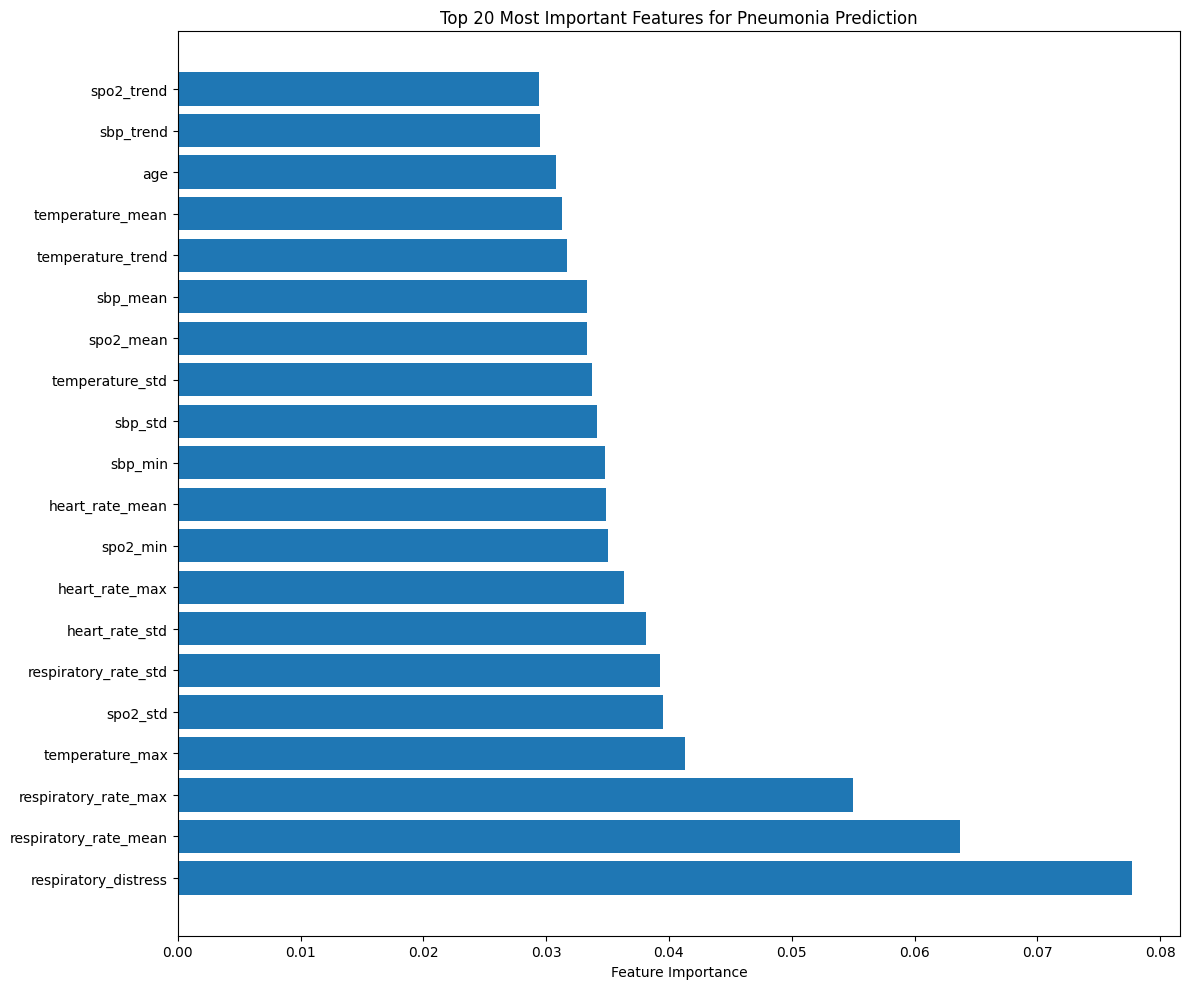

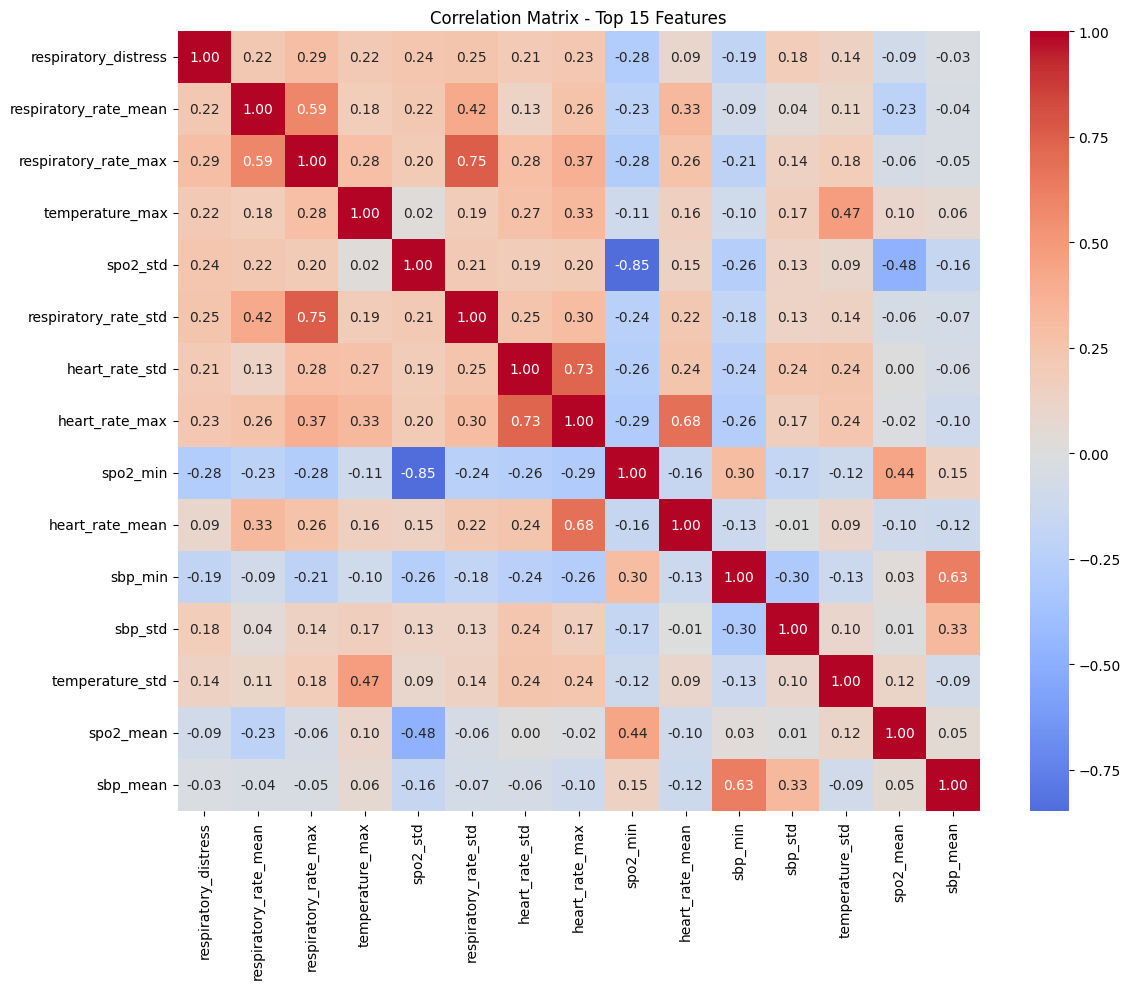

In [15]:
# ============================================
# STEP 9: FEATURE SELECTION PREPARATION
# ============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectKBest, f_classif, RFE
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

print("=" * 70)
print("STEP 9: Feature Selection Preparation")
print("=" * 70)

# Load the final dataset
df = pd.read_csv("pneumonia_dataset_final.csv")
print(f"✅ Loaded dataset: {df.shape}")
print(f"   Features: {len(df.columns) - 2} (excluding ID and label)")
print(f"   Patients: {len(df)}")

# Separate features and target
X = df.drop(['hadm_id', 'pneumonia_label'], axis=1)
y = df['pneumonia_label']

print(f"\n📊 Feature matrix: {X.shape}")
print(f"   Target: {y.shape}")

# ============================================
# 1. Train/Test Split
# ============================================

print("\n📋 Train/Test Split...")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"   Training: {X_train.shape[0]} samples")
print(f"   Test: {X_test.shape[0]} samples")
print(f"   Training Pneumonia: {y_train.sum()} ({y_train.sum()/len(y_train)*100:.1f}%)")
print(f"   Test Pneumonia: {y_test.sum()} ({y_test.sum()/len(y_test)*100:.1f}%)")

# ============================================
# 2. Feature Importance (Random Forest)
# ============================================

print("\n🌲 Calculating Feature Importance...")

rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

importance_df = pd.DataFrame({
    'feature': X.columns,
    'importance': rf.feature_importances_
}).sort_values('importance', ascending=False)

print(f"\n📊 Top 15 Most Important Features:")
print("-" * 60)
for i, row in importance_df.head(15).iterrows():
    print(f"   {i+1:2d}. {row['feature']}: {row['importance']:.4f}")

# ============================================
# 3. Plot Feature Importance
# ============================================

plt.figure(figsize=(12, 10))
plt.barh(importance_df.head(20)['feature'], importance_df.head(20)['importance'])
plt.xlabel('Feature Importance')
plt.title('Top 20 Most Important Features for Pneumonia Prediction')
plt.tight_layout()
plt.savefig('feature_importance_step9.png', dpi=150)
print("\n✅ Saved feature_importance_step9.png")

# ============================================
# 4. Correlation Heatmap (Top Features)
# ============================================

plt.figure(figsize=(12, 10))
top_features = importance_df.head(15)['feature'].tolist()
corr_matrix = X[top_features].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('Correlation Matrix - Top 15 Features')
plt.tight_layout()
plt.savefig('correlation_matrix_step9.png', dpi=150)
print("✅ Saved correlation_matrix_step9.png")

# ============================================
# 5. Summary
# ============================================

print("\n" + "=" * 70)
print("📊 FEATURE SELECTION PREPARATION SUMMARY")
print("=" * 70)

print(f"""
Total Features: {X.shape[1]}

Top 5 Most Important Features:
1. {importance_df.iloc[0]['feature']}: {importance_df.iloc[0]['importance']:.4f}
2. {importance_df.iloc[1]['feature']}: {importance_df.iloc[1]['importance']:.4f}
3. {importance_df.iloc[2]['feature']}: {importance_df.iloc[2]['importance']:.4f}
4. {importance_df.iloc[3]['feature']}: {importance_df.iloc[3]['importance']:.4f}
5. {importance_df.iloc[4]['feature']}: {importance_df.iloc[4]['importance']:.4f}

Class Imbalance: {y.sum()}/{len(y)-y.sum()} ({y.sum()/len(y)*100:.1f}% Pneumonia)
   → Use class weights during training

Next Steps:
1. Run Step 10: ML-based Feature Selection (RFE, SelectKBest)
2. Run Step 11: Train Models with Selected Features
3. Run Step 12: Hyperparameter Tuning
4. Run Step 13: Final Evaluation
""")

print("=" * 70)
print("✅ STEP 9 COMPLETE!")
print("=" * 70)